# Лабораторная работа: математический анализ и матричное исчисление

**Выполнил:** Фролов А.А., 3 курс, группа ИВТ-2.3  
**Дисциплина:** Математика для ИИ, лабораторная работа №1

## Назначение работы

Эта лабораторная работа учит читать сложные формулы как точные инструкции над числами, векторами, матрицами и тензорами. Мы начнём с сумм и индексов, перейдём к производной обычной функции, затем последовательно построим градиент, производную по направлению, полную производную, якобиан, произведения с якобианом, гессиан и матричные градиенты. В конце все операторы соединятся в одной составной параметрической функции, для которой будут вручную выведены производные, выполнена численная проверка и проведена оптимизация.

Работа образует одну непрерывную канву. Каждый следующий объект отвечает на ограничение предыдущего: одной производной недостаточно для функции многих переменных; одного градиента недостаточно для векторного выхода; полный якобиан не всегда следует строить явно; первая производная показывает направление изменения, а гессиан — изменение самого градиента и локальную кривизну.

Единственный источник теории, формул и соглашений об обозначениях — пособие «Линейная алгебра». Из «Высшей математики. Практикума» перенесены только несколько начальных условий для ручного решения. Остальные аналитические и вычислительные задания специально составлены для этой работы.

## Как выполнять работу

Этапы помечены способом работы:

- **[Бумага]** — вывести результат аналитически без NumPy;
- **[Markdown]** — оформить рассуждение и формулы в Markdown-ячейке;
- **[Python]** — проверить вывод или исследовать численное поведение;
- **[Интерпретация]** — объяснить тип, размерность и практический смысл результата.

Сначала выполняйте пункт **[Бумага]**, затем переносите решение в ноутбук и только после этого запускайте проверочный код. Численное совпадение не заменяет вывода: программа проверяет формулу в выбранной точке, но не доказывает её для всех допустимых аргументов.

Для каждой сложной формулы придерживайтесь четырёх вопросов:

1. Каков тип входа: скаляр, вектор, матрица или тензор?
2. Какие индексы свободны, а по каким выполняется суммирование?
3. Какова размерность результата?
4. Можно ли вычислить нужное произведение, не формируя большую производную целиком?

### Единая траектория

1. Сумма по индексам превращается в матричное или тензорное произведение.
2. Предел отношения приращений определяет локальную скорость изменения.
3. Частные производные собираются в градиент.
4. Градиент задаёт изменение в выбранном направлении.
5. Производные векторной функции собираются в якобиан.
6. Цепное правило превращается в произведение якобианов или векторно-якобианное произведение.
7. Вторые частные производные образуют гессиан и описывают кривизну.
8. Индексные выводы сворачиваются в компактные матричные градиенты.
9. Градиенты составной функции проверяются конечными разностями.
10. Проверенные градиенты используются для уменьшения целевой функции.

## Соглашения и общий пакет данных

Градиент скалярной функции $f:\mathbb R^n\to\mathbb R$ считаем вектором-столбцом. Для отображения $\mathbf f:\mathbb R^n\to\mathbb R^m$ используем якобиан, строки которого соответствуют компонентам выхода:

$$
\mathbf J_{\mathbf f}(\mathbf x)
=\frac{\partial\mathbf f}{\partial\mathbf x^{\mathsf T}}
\in\mathbb R^{m\times n}.
$$

Сквозной вычислительный пример использует пакет из $N=4$ наблюдений, $D=3$ входных координат и $K=2$ выходных координат:

$$
\mathbf X=
\begin{pmatrix}
1&0&-1\\
0&1&1\\
1&1&0\\
-1&2&1
\end{pmatrix}\in\mathbb R^{4\times3},
\qquad
\mathbf Y=
\begin{pmatrix}
0.2&0.8\\
0.7&0.1\\
0.6&0.4\\
0.1&0.9
\end{pmatrix}\in\mathbb R^{4\times2}.
$$

Начальные параметры:

$$
\mathbf W_0=
\begin{pmatrix}
0.2&-0.3\\
0.4&0.1\\
-0.5&0.2
\end{pmatrix}\in\mathbb R^{3\times2},
\qquad
\mathbf b_0=
\begin{pmatrix}0.1\\-0.2\end{pmatrix},
\qquad \lambda=0.05.
$$

В конце работы вычисляется композиция

$$
\mathbf Z=\mathbf X\mathbf W+\mathbf1_N\mathbf b^{\mathsf T},
\qquad
\mathbf H=\sigma(\mathbf Z),
\qquad
\sigma(z)=\frac{1}{1+e^{-z}},
$$

и скалярная целевая функция

$$
\mathcal L(\mathbf W,\mathbf b)
=\frac{1}{2N}\lVert\mathbf H-\mathbf Y\rVert_F^2
+\frac{\lambda}{2}\lVert\mathbf W\rVert_F^2.
$$

Пока не дифференцируйте эту запись: к ней будем возвращаться после освоения каждого необходимого оператора.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

X_data = np.array([
    [1, 0, -1],
    [0, 1, 1],
    [1, 1, 0],
    [-1, 2, 1],
], dtype=float)

Y_data = np.array([
    [0.2, 0.8],
    [0.7, 0.1],
    [0.6, 0.4],
    [0.1, 0.9],
], dtype=float)

W_initial = np.array([
    [0.2, -0.3],
    [0.4, 0.1],
    [-0.5, 0.2],
], dtype=float)

b_initial = np.array([0.1, -0.2], dtype=float)
regularization = 0.05

def sigmoid(z):
    """Устойчивая поэлементная сигмоида."""
    z_safe = np.clip(z, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-z_safe))

print("X:", X_data.shape, "Y:", Y_data.shape)
print("W:", W_initial.shape, "b:", b_initial.shape)
print("lambda =", regularization)


X: (4, 3) Y: (4, 2)
W: (3, 2) b: (2,)
lambda = 0.05


## 1. Суммы, индексы и матричная запись

### Короткая теория

Если $\mathbf A\in\mathbb R^{m\times n}$ и $\mathbf B\in\mathbb R^{n\times p}$, то

$$
\mathbf C=\mathbf A\mathbf B\in\mathbb R^{m\times p},
\qquad
C_{ij}=\sum_{k=1}^{n}A_{ik}B_{kj}.
$$

Индексы $i$ и $j$ свободны: они остаются у результата. Индекс $k$ суммируемый, или фиктивный: он пробегает допустимые значения и исчезает после суммирования. В нотации Эйнштейна знак суммы можно опустить, если правило суммирования однозначно. См. матричное произведение, с. 15–18 и суммирование Эйнштейна, с. 20.

### Задание 1.1. От суммы к матрице

Даны

$$
\mathbf A=
\begin{pmatrix}1&2&-1\\0&3&1\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}2&1\\1&-1\\0&2\end{pmatrix}.
$$

- **[Бумага]** Укажите размеры $\mathbf A$, $\mathbf B$ и $\mathbf C=\mathbf A\mathbf B$. Распишите каждый $C_{ij}$ отдельной суммой.
- **[Markdown]** Подпишите свободные и суммируемый индексы в $C_{ij}=\sum_kA_{ik}B_{kj}$.
- **[Python]** Сравните ручной результат с `A @ B` и с тройным циклом по $i,j,k$.
- **[Интерпретация]** Объясните, почему индекс $k$ отсутствует в обозначении $C_{ij}$ и почему поменять местами $j$ и $k$ нельзя.

#### Ваше решение

**Аналитическая часть.**

Размеры: $\mathbf A\in\mathbb R^{2\times3}$, $\mathbf B\in\mathbb R^{3\times2}$. Внутренние размеры совпадают ($3=3$), поэтому произведение определено и $\mathbf C=\mathbf A\mathbf B\in\mathbb R^{2\times2}$.

$$
C_{ij}=\sum_{k=1}^{3}A_{ik}B_{kj},\qquad i\in\{1,2\},\ j\in\{1,2\}.
$$

$$
\begin{aligned}
C_{11}&=A_{11}B_{11}+A_{12}B_{21}+A_{13}B_{31}=1\cdot2+2\cdot1+(-1)\cdot0=4,\\
C_{12}&=A_{11}B_{12}+A_{12}B_{22}+A_{13}B_{32}=1\cdot1+2\cdot(-1)+(-1)\cdot2=-3,\\
C_{21}&=A_{21}B_{11}+A_{22}B_{21}+A_{23}B_{31}=0\cdot2+3\cdot1+1\cdot0=3,\\
C_{22}&=A_{21}B_{12}+A_{22}B_{22}+A_{23}B_{32}=0\cdot1+3\cdot(-1)+1\cdot2=-1.
\end{aligned}
\qquad\Longrightarrow\qquad
\mathbf C=\begin{pmatrix}4&-3\\3&-1\end{pmatrix}.
$$

**Индексы.** В записи

$$
C_{\underbrace{i}_{\text{свободный}}\,\underbrace{j}_{\text{свободный}}}
=\sum_{\underbrace{k}_{\text{суммируемый}}}A_{ik}B_{kj}
$$

индекс $i$ нумерует строку $\mathbf A$ (и строку $\mathbf C$), $j$ — столбец $\mathbf B$ (и столбец $\mathbf C$). Индекс $k$ — немой: он одновременно нумерует столбец $\mathbf A$ и строку $\mathbf B$. В нотации Эйнштейна: $C_{ij}=A_{ik}B_{kj}$.

**Численная проверка и интерпретация.**

Ручной расчёт, `A @ B` и тройной цикл дают одну и ту же матрицу $\begin{pmatrix}4&-3\\3&-1\end{pmatrix}$ (вывод ниже).

Индекса $k$ нет в $C_{ij}$, потому что по нему мы уже просуммировали. Элемент $C_{ij}$ зависит только от того, какую строку $\mathbf A$ и какой столбец $\mathbf B$ мы взяли.

Поменять $j$ и $k$ нельзя: $k$ пробегает столбцы $\mathbf A$ и строки $\mathbf B$ (их по 3), а $j$ — столбцы $\mathbf B$ (их 2). Если суммировать по $j$, получится $\sum_j A_{ij}B_{kj}$, то есть уже другая операция ($\mathbf A\mathbf B^{\mathsf T}$), и тут она даже не определена по размерам.

In [2]:
A = np.array([[1, 2, -1], [0, 3, 1]], dtype=float)
B = np.array([[2, 1], [1, -1], [0, 2]], dtype=float)
print("A:", A.shape, " B:", B.shape, " ожидаемая форма C:", (A.shape[0], B.shape[1]))

# Ручной расчёт: каждая C_ij как отдельная сумма по k.
C_manual = np.array([
    [1*2 + 2*1 + (-1)*0, 1*1 + 2*(-1) + (-1)*2],
    [0*2 + 3*1 + 1*0,    0*1 + 3*(-1) + 1*2],
], dtype=float)

C_matmul = A @ B

m, n = A.shape
p = B.shape[1]
C_loops = np.zeros((m, p))
for i in range(m):          # свободный индекс
    for j in range(p):      # свободный индекс
        for k in range(n):  # суммируемый индекс
            C_loops[i, j] += A[i, k] * B[k, j]

print("C вручную:\n", C_manual)
print("C = A @ B:\n", C_matmul)
print("C тройным циклом:\n", C_loops)
print("Все три совпадают:", np.allclose(C_manual, C_matmul) and np.allclose(C_loops, C_matmul))

A: (2, 3)  B: (3, 2)  ожидаемая форма C: (2, 2)
C вручную:
 [[ 4. -3.]
 [ 3. -1.]]
C = A @ B:
 [[ 4. -3.]
 [ 3. -1.]]
C тройным циклом:
 [[ 4. -3.]
 [ 3. -1.]]
Все три совпадают: True


### Задание 1.2. Три индекса и две свёртки

Рассмотрим тензор $S_{ntk}$ и матрицы $W_{kd}$, $V_{dc}$:

$$
S=
\left[
\begin{pmatrix}1&0&0\\0&1&0\end{pmatrix},
\begin{pmatrix}0&1&0\\0&0&1\end{pmatrix}
\right],
$$

$$
\mathbf W=
\begin{pmatrix}1&0\\0&2\\1&-1\end{pmatrix},
\qquad
\mathbf V=
\begin{pmatrix}1&-1\\2&1\end{pmatrix}.
$$

Определим

$$
L_{nc}=\sum_{t=1}^{2}\sum_{k=1}^{3}\sum_{d=1}^{2}
S_{ntk}W_{kd}V_{dc}.
$$

- **[Бумага]** Укажите размер каждого объекта и результата. Для $L_{11}$ выпишите все слагаемые до удаления нулей.
- **[Markdown]** Объясните, почему $n,c$ свободны, а $t,k,d$ суммируются. Запишите то же выражение в нотации Эйнштейна.
- **[Интерпретация]** Опишите вычисление как последовательность двух более простых преобразований с промежуточной матрицей $E_{nd}$.

#### Ваше решение

**Аналитическая часть.**

| Объект | Индексы | Диапазоны | Размер |
|---|---|---|---|
| $S_{ntk}$ | $n,t,k$ | $n=1..2,\ t=1..2,\ k=1..3$ | $2\times2\times3$ |
| $W_{kd}$ | $k,d$ | $k=1..3,\ d=1..2$ | $3\times2$ |
| $V_{dc}$ | $d,c$ | $d=1..2,\ c=1..2$ | $2\times2$ |
| $L_{nc}$ | $n,c$ | $n=1..2,\ c=1..2$ | $2\times2$ |

**Все $2\cdot3\cdot2=12$ слагаемых $L_{11}$.** Здесь $S_{111}=1,\ S_{112}=0,\ S_{113}=0,\ S_{121}=0,\ S_{122}=1,\ S_{123}=0$ и $V_{11}=1,\ V_{21}=2$:

$$
\begin{aligned}
L_{11}=\;&S_{111}W_{11}V_{11}+S_{111}W_{12}V_{21}+S_{112}W_{21}V_{11}+S_{112}W_{22}V_{21}+S_{113}W_{31}V_{11}+S_{113}W_{32}V_{21}\\
&+S_{121}W_{11}V_{11}+S_{121}W_{12}V_{21}+S_{122}W_{21}V_{11}+S_{122}W_{22}V_{21}+S_{123}W_{31}V_{11}+S_{123}W_{32}V_{21}\\
=\;&1\cdot1\cdot1+1\cdot0\cdot2+0\cdot0\cdot1+0\cdot2\cdot2+0\cdot1\cdot1+0\cdot(-1)\cdot2\\
&+0\cdot1\cdot1+0\cdot0\cdot2+1\cdot0\cdot1+1\cdot2\cdot2+0\cdot1\cdot1+0\cdot(-1)\cdot2\\
=\;&1+4=5.
\end{aligned}
$$

**Свободные и суммируемые индексы.** $n$ и $c$ есть в левой части $L_{nc}$, значит они свободные: для каждой пары $(n,c)$ получается своё число, результат — матрица $2\times2$. Индексы $t,k,d$ есть только справа под знаком суммы, по ним суммируем, и в ответе их нет.

**Нотация Эйнштейна** (суммируем по всем индексам, которых нет в левой части):

$$
L_{nc}=S_{ntk}W_{kd}V_{dc}.
$$

**Два простых преобразования.**

1. Сворачиваем $t$ и $k$: $\;E_{nd}=\sum_t\sum_k S_{ntk}W_{kd}$. Сначала $P_{nk}=\sum_t S_{ntk}$ даёт $\mathbf P=\begin{pmatrix}1&1&0\\0&1&1\end{pmatrix}$, затем
   $\mathbf E=\mathbf P\mathbf W=\begin{pmatrix}1&2\\1&1\end{pmatrix}\in\mathbb R^{2\times2}$.
2. Сворачиваем $d$: $\;L_{nc}=\sum_d E_{nd}V_{dc}$, то есть $\mathbf L=\mathbf E\mathbf V=\begin{pmatrix}1\cdot1+2\cdot2&1\cdot(-1)+2\cdot1\\1\cdot1+1\cdot2&1\cdot(-1)+1\cdot1\end{pmatrix}=\begin{pmatrix}5&1\\3&0\end{pmatrix}$.

**Численная проверка и интерпретация.**

Код ниже выводит ожидаемые формы $E_{nd}$: $(2,2)$ и $L_{nc}$: $(2,2)$ и все 12 слагаемых $L_{11}$. Их сумма равна $5$, как и вручную. То есть тройную сумму можно посчитать в два шага: сначала свернуть $S$ с $\mathbf W$ (получаем $\mathbf E$), потом умножить $\mathbf E$ на $\mathbf V$.

In [3]:
S_tensor = np.array([
    [[1, 0, 0], [0, 1, 0]],
    [[0, 1, 0], [0, 0, 1]],
], dtype=float)
W_tensor = np.array([[1, 0], [0, 2], [1, -1]], dtype=float)
V_tensor = np.array([[1, -1], [2, 1]], dtype=float)

print("S:", S_tensor.shape, "W:", W_tensor.shape, "V:", V_tensor.shape)

n_size, t_size, k_size = S_tensor.shape
d_size, c_size = V_tensor.shape
assert W_tensor.shape == (k_size, d_size)
print("Ожидаемая форма E_nd:", (n_size, d_size))
print("Ожидаемая форма L_nc:", (n_size, c_size))

# Все 12 слагаемых L_11 (n=0, c=0 в индексации Python) до удаления нулей.
terms_L11 = []
for t in range(t_size):
    for k in range(k_size):
        for d in range(d_size):
            terms_L11.append(float(S_tensor[0, t, k] * W_tensor[k, d] * V_tensor[d, 0]))
print("Слагаемые L_11:", terms_L11)
print("L_11 =", sum(terms_L11))

S: (2, 2, 3) W: (3, 2) V: (2, 2)
Ожидаемая форма E_nd: (2, 2)
Ожидаемая форма L_nc: (2, 2)
Слагаемые L_11: [1.0, 0.0, 0.0, 0.0, 0.0, -0.0, 0.0, 0.0, 0.0, 4.0, 0.0, -0.0]
L_11 = 5.0


### Задание 1.3. Циклы, матрицы и `einsum`

- **[Python]** Вычислите $L_{nc}$ четырьмя способами: вложенными циклами, через промежуточную матрицу $E$, одним `np.einsum` и двумя последовательными `np.einsum`.
- **[Markdown]** Запишите строки индексов для `einsum` и сопоставьте их математическим индексам.
- **[Интерпретация]** Объясните, почему совпадение четырёх реализаций является хорошей проверкой индексов, но не заменяет проверки размерностей до запуска.

#### Ваше решение

**Аналитическая часть.**

Четыре реализации одной и той же формулы $L_{nc}=\sum_t\sum_k\sum_d S_{ntk}W_{kd}V_{dc}$:

1. **Вложенные циклы** по всем пяти индексам $n,c,t,k,d$, всего $2\cdot2\cdot2\cdot3\cdot2=48$ умножений.
2. **Через промежуточную матрицу:** $\mathbf E=\big(\sum_t S_{nt\,\cdot}\big)\mathbf W$, затем $\mathbf L=\mathbf E\mathbf V$.
3. **Один `einsum`:** `np.einsum("ntk,kd,dc->nc", S, W, V)`.
4. **Два `einsum`:** `E = np.einsum("ntk,kd->nd", S, W)`, затем `L = np.einsum("nd,dc->nc", E, V)`.

**Соответствие строк `einsum` математическим индексам.**

| Строка | Операнд | Математический объект |
|---|---|---|
| `ntk` | `S_tensor` | $S_{ntk}$ |
| `kd` | `W_tensor` | $W_{kd}$ |
| `dc` | `V_tensor` | $V_{dc}$ |
| `->nc` | результат | $L_{nc}$: буквы справа от `->` свободные, остальные (`t`, `k`, `d`) суммируются |
| `ntk,kd->nd` | шаг 1 | $E_{nd}=\sum_{t,k}S_{ntk}W_{kd}$ |
| `nd,dc->nc` | шаг 2 | $L_{nc}=\sum_d E_{nd}V_{dc}$ |

**Численная проверка и интерпретация.**

Все четыре способа дают $\mathbf L=\begin{pmatrix}5&1\\3&0\end{pmatrix}$ при $\mathbf E=\begin{pmatrix}1&2\\1&1\end{pmatrix}$, что совпадает с ручным выводом.

Совпадение — хорошая проверка: способы записаны по-разному, и одна и та же ошибка в индексах вряд ли будет во всех четырёх. Но проверку размерностей это не заменяет. Если я с самого начала неправильно понял формулу (например, перепутал $W_{kd}$ и $W_{dk}$), все четыре способа ошибутся одинаково. К тому же $\mathbf E$ и $\mathbf V$ квадратные ($2\times2$), и перепутанные индексы не дадут ошибку формы, а просто дадут неверный ответ. Поэтому сначала проверяем размеры: $(2,2,3)$ и $(3,2)$ дают $(2,2)$, потом $(2,2)\cdot(2,2)\to(2,2)$.

In [4]:
# 1) Вложенные циклы
L_loops = np.zeros((n_size, c_size))
for n in range(n_size):
    for c in range(c_size):
        for t in range(t_size):
            for k in range(k_size):
                for d in range(d_size):
                    L_loops[n, c] += S_tensor[n, t, k] * W_tensor[k, d] * V_tensor[d, c]

# 2) Через промежуточную матрицу E_nd = sum_t sum_k S_ntk W_kd
E_matrix = S_tensor.sum(axis=1) @ W_tensor
L_matrix = E_matrix @ V_tensor

# 3) Один einsum
L_einsum_once = np.einsum("ntk,kd,dc->nc", S_tensor, W_tensor, V_tensor)

# 4) Два последовательных einsum
E_einsum = np.einsum("ntk,kd->nd", S_tensor, W_tensor)
L_einsum_twice = np.einsum("nd,dc->nc", E_einsum, V_tensor)

print("E_nd:\n", E_matrix, "  форма", E_matrix.shape)
for name, value in [("циклы", L_loops), ("через E", L_matrix),
                    ("einsum x1", L_einsum_once), ("einsum x2", L_einsum_twice)]:
    print(f"L ({name}):\n", value)
print("Все четыре совпадают:",
      all(np.allclose(L_loops, other) for other in (L_matrix, L_einsum_once, L_einsum_twice)))

E_nd:
 [[1. 2.]
 [1. 1.]]   форма (2, 2)
L (циклы):
 [[5. 1.]
 [3. 0.]]
L (через E):
 [[5. 1.]
 [3. 0.]]
L (einsum x1):
 [[5. 1.]
 [3. 0.]]
L (einsum x2):
 [[5. 1.]
 [3. 0.]]
Все четыре совпадают: True


## 2. Функции одной переменной

### Короткая теория

Производная функции $f:\mathbb R\to\mathbb R$ в точке $x$ определяется пределом

$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.
$$

Для малого $h$ функция локально заменяется касательной:

$$
f(x+h)\approx f(x)+f'(x)h.
$$

Прямую, центральную и обратную конечные разности, а также причину потери точности при слишком малом $h$ см. в теории, с. 39–40. Правила для степенной, экспоненциальной, логарифмической и сложной функций приведены на с. 42.

### Задание 2.1. Производная как предел и как численный оператор

Для $f(x)=e^x$ и $x_0=1$ рассмотрите

$$
D_+(h)=\frac{f(x_0+h)-f(x_0)}{h},
\quad
D_0(h)=\frac{f(x_0+h/2)-f(x_0-h/2)}{h},
\quad
D_-(h)=\frac{f(x_0)-f(x_0-h)}{h}.
$$

- **[Бумага]** Найдите точную производную и уравнение касательной в $x_0$.
- **[Markdown]** Объясните, почему все три выражения стремятся к одному числу, но при конечном $h$ имеют разные ошибки.
- **[Python]** Для $h=10^{-1},\ldots,10^{-16}$ вычислите абсолютные ошибки и постройте логарифмический график. Отдельно покажите функцию и касательную около $x_0$.
- **[Интерпретация]** Найдите область лучших $h$ и объясните рост ошибки при чрезмерно малом шаге вычитанием близких чисел.

#### Ваше решение

**Аналитическая часть.**

$f(x)=e^x$, $\;f'(x)=e^x$, поэтому $f'(1)=e\approx2.718281828$.

Касательная в $x_0=1$: $\;y=f(x_0)+f'(x_0)(x-x_0)=e+e(x-1)=e\,x$.

**Почему ошибки разные.** Разложим $f$ по Тейлору около $x_0$:
$f(x_0\pm h)=f\pm f'h+\tfrac12f''h^2\pm\tfrac16f'''h^3+\dots$

$$
D_+(h)=f'+\frac{f''}{2}h+O(h^2),\qquad
D_-(h)=f'-\frac{f''}{2}h+O(h^2),\qquad
D_0(h)=f'+\frac{f'''}{24}h^2+O(h^4).
$$

Все три выражения стремятся к $f'(x_0)$ при $h\to0$: это следует из определения производной как предела. Но при конечном $h$ ошибка усечения у них разная. У односторонних разностей она первого порядка ($\approx\frac e2h$, со знаком «$+$» у $D_+$ и «$-$» у $D_-$). В центральной разности чётные члены сокращаются, и ошибка получается второго порядка ($\approx\frac e{24}h^2$).

Кроме того, в арифметике с плавающей точкой есть ошибка округления. Числитель вычисляется с абсолютной погрешностью порядка $\varepsilon\,|f|$, где $\varepsilon\approx2.2\cdot10^{-16}$, а затем делится на $h$:

$$
\text{ошибка}(h)\approx C h^p+\frac{\varepsilon\,e}{h}.
$$

Минимум этой суммы достигается при $h_*\sim\sqrt\varepsilon\approx10^{-8}$ для $p=1$ и при $h_*\sim\varepsilon^{1/3}\approx10^{-5}$ для $p=2$.

**Численная проверка и интерпретация.**

* **Прямая и обратная разности.** Ошибка падает в 10 раз на каждый порядок $h$: $0.14$ при $h=10^{-1}$, $1.36\cdot10^{-2}$ при $10^{-2}$, … Коэффициент $\approx1.36=e/2$, как и предсказано. Лучший результат $\approx6.6\cdot10^{-9}$ получается при $h=10^{-8}$.
* **Центральная разность.** Ошибка падает в 100 раз на порядок $h$: $1.133\cdot10^{-3}$ при $h=10^{-1}$, где $e/24\cdot10^{-2}=1.133\cdot10^{-3}$, точное совпадение с теорией. Лучший результат $\approx5.9\cdot10^{-11}$ получается при $h=10^{-5}$–$10^{-6}$.
* **Слишком малый шаг.** Левее оптимума ошибка *растёт*: при $h=10^{-12}$ она уже $\sim10^{-4}$–$10^{-5}$, при $h=10^{-15}$ — $\sim10^{-1}$. При $h=10^{-16}$ все три формулы дают $0$, и ошибка равна самой производной $e$: число $1+10^{-16}$ в `float64` неотличимо от $1$, поэтому числитель равен нулю.

Причина — вычитание близких чисел: $f(x_0+h)$ и $f(x_0)$ почти равны, после вычитания остаются только последние неточные знаки, а деление на маленькое $h$ эту погрешность увеличивает. Лучшие шаги: $h\approx10^{-8}$ для односторонних разностей и $h\approx10^{-5}$–$10^{-6}$ для центральной.

На правом графике видно, что касательная $y=ex$ почти совпадает с $e^x$ около $x_0=1$, а дальше от точки расходится с ней.

f'(1) = e = 2.718281828459

       h |    |D+ - e| |    |D0 - e| |    |D- - e|
   1e-01 |   1.406e-01 |   1.133e-03 |   1.315e-01
   1e-02 |   1.364e-02 |   1.133e-05 |   1.355e-02
   1e-03 |   1.360e-03 |   1.133e-07 |   1.359e-03
   1e-04 |   1.359e-04 |   1.133e-09 |   1.359e-04
   1e-05 |   1.359e-05 |   5.859e-11 |   1.359e-05
   1e-06 |   1.359e-06 |   5.859e-11 |   1.359e-06
   1e-07 |   1.399e-07 |   2.162e-09 |   1.398e-07
   1e-08 |   6.603e-09 |   6.603e-09 |   6.603e-09
   1e-09 |   2.154e-07 |   2.154e-07 |   2.286e-07
   1e-10 |   1.548e-06 |   1.548e-06 |   2.893e-06
   1e-11 |   3.263e-05 |   1.177e-05 |   1.177e-05
   1e-12 |   4.323e-04 |   1.177e-05 |   1.177e-05
   1e-13 |   4.559e-04 |   4.897e-03 |   4.559e-04
   1e-14 |   9.338e-03 |   3.507e-02 |   9.338e-03
   1e-15 |   3.903e-01 |   5.375e-02 |   5.375e-02
   1e-16 |   2.718e+00 |   2.718e+00 |   2.718e+00
Лучший h для прямая      : 1e-08, ошибка 6.60e-09
Лучший h для центральная : 1e-05, ошибка 5.86e-11
Лучши

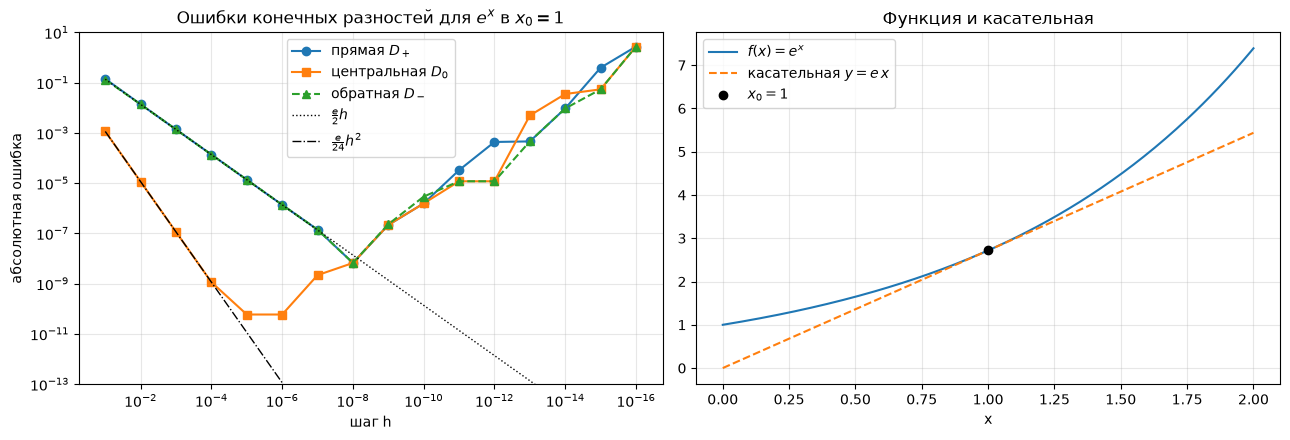

In [5]:
x0 = 1.0
h_values = np.logspace(-1, -16, 16)
exact_derivative = np.exp(x0)  # (e^x)' = e^x

f = np.exp
D_forward = (f(x0 + h_values) - f(x0)) / h_values
D_central = (f(x0 + h_values / 2) - f(x0 - h_values / 2)) / h_values
D_backward = (f(x0) - f(x0 - h_values)) / h_values

err_forward = np.abs(D_forward - exact_derivative)
err_central = np.abs(D_central - exact_derivative)
err_backward = np.abs(D_backward - exact_derivative)

print(f"f'(1) = e = {exact_derivative:.12f}\n")
print(f"{'h':>8} | {'|D+ - e|':>11} | {'|D0 - e|':>11} | {'|D- - e|':>11}")
for h, ef, ec, eb in zip(h_values, err_forward, err_central, err_backward):
    print(f"{h:8.0e} | {ef:11.3e} | {ec:11.3e} | {eb:11.3e}")
for name, err in [("прямая", err_forward), ("центральная", err_central), ("обратная", err_backward)]:
    i = np.argmin(err)
    print(f"Лучший h для {name:12s}: {h_values[i]:.0e}, ошибка {err[i]:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(h_values, err_forward, "o-", label="прямая $D_+$")
axes[0].loglog(h_values, err_central, "s-", label="центральная $D_0$")
axes[0].loglog(h_values, err_backward, "^--", label="обратная $D_-$")
axes[0].loglog(h_values, exact_derivative / 2 * h_values, "k:", lw=1, label=r"$\frac{e}{2}h$")
axes[0].loglog(h_values, exact_derivative / 24 * h_values**2, "k-.", lw=1, label=r"$\frac{e}{24}h^2$")
axes[0].set_ylim(1e-13, 1e1)
axes[0].invert_xaxis()
axes[0].set_xlabel("шаг h")
axes[0].set_ylabel("абсолютная ошибка")
axes[0].set_title("Ошибки конечных разностей для $e^x$ в $x_0=1$")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

x_grid = np.linspace(0, 2, 200)
axes[1].plot(x_grid, np.exp(x_grid), label="$f(x)=e^x$")
axes[1].plot(x_grid, exact_derivative * x_grid, "--", label="касательная $y=e\\,x$")
axes[1].plot([x0], [np.exp(x0)], "ko", label="$x_0=1$")
axes[1].set_xlabel("x")
axes[1].set_title("Функция и касательная")
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()

### Задание 2.2. Правила дифференцирования

Источник условий: практикум, с. 71, задачи 1, 2, 4 и 6.

Найдите производные и вычислите их при $x=1$:

$$
\begin{aligned}
&1)\quad y=2x^3-5x^2+7x+4;\\
&2)\quad y=x^2e^x;\\
&3)\quad y=(2x^2+5)^2;\\
&4)\quad y=\ln(2x^3+3x^2).
\end{aligned}
$$

- **[Бумага]** Для каждой функции назовите используемые правила и сохраните производную как функцию от $x$ до подстановки.
- **[Markdown]** Особо выделите внешний и внутренний аргументы в пунктах 3 и 4.
- **[Python]** Проверьте значения центральной разностью при $h=10^{-5}$.
- **[Интерпретация]** Сравните знаки и модули производных как локальные скорости изменения четырёх разных функций.

#### Ваше решение

**Аналитическая часть.**

1. $y=2x^3-5x^2+7x+4$. Правила: линейность и степенная функция $(x^n)'=nx^{n-1}$.
   $$y'=6x^2-10x+7,\qquad y'(1)=6-10+7=3.$$
2. $y=x^2e^x$. Правило произведения $(uv)'=u'v+uv'$:
   $$y'=2xe^x+x^2e^x=e^x(x^2+2x),\qquad y'(1)=3e\approx8.154845.$$
3. $y=(2x^2+5)^2$. Сложная функция $y=g(u(x))$, **внешняя** функция $g(u)=u^2$, **внутренний** аргумент $u=2x^2+5$:
   $$y'=g'(u)\,u'(x)=2u\cdot4x=8x(2x^2+5),\qquad y'(1)=8\cdot7=56.$$
4. $y=\ln(2x^3+3x^2)$. Сложная функция, **внешняя** $g(u)=\ln u$, **внутренний** аргумент $u=2x^3+3x^2$ (область определения $u>0$):
   $$y'=\frac{1}{u}\,u'(x)=\frac{6x^2+6x}{2x^3+3x^2}=\frac{6(x+1)}{x(2x+3)},\qquad y'(1)=\frac{12}{5}=2.4.$$

**Численная проверка и интерпретация.**

Центральная разность при $h=10^{-5}$ совпадает со всеми четырьмя аналитическими значениями с ошибкой порядка $10^{-10}$ или меньше (таблица ниже).

Все производные в $x=1$ положительны, значит все четыре функции в этой точке возрастают. Различаются модули, то есть скорости:

| Функция | $y'(1)$ | Изменение $y$ при $\Delta x=0.01$ |
|---|---|---|
| $(2x^2+5)^2$ | $56$ | $\approx+0.56$ — самая быстрая |
| $x^2e^x$ | $8.15$ | $\approx+0.082$ |
| многочлен | $3$ | $\approx+0.03$ |
| $\ln(2x^3+3x^2)$ | $2.4$ | $\approx+0.024$ — самая медленная: логарифм «сжимает» рост внутреннего аргумента |

In [6]:
x0 = 1.0
h = 1e-5

functions = [
    lambda x: 2*x**3 - 5*x**2 + 7*x + 4,
    lambda x: x**2 * np.exp(x),
    lambda x: (2*x**2 + 5)**2,
    lambda x: np.log(2*x**3 + 3*x**2),
]

derivatives = [
    lambda x: 6*x**2 - 10*x + 7,              # степенная функция + линейность
    lambda x: np.exp(x) * (x**2 + 2*x),       # произведение
    lambda x: 8*x * (2*x**2 + 5),             # цепное правило: 2u * u'
    lambda x: 6*(x + 1) / (x * (2*x + 3)),    # цепное правило: u'/u
]
names = ["2x^3-5x^2+7x+4", "x^2 e^x", "(2x^2+5)^2", "ln(2x^3+3x^2)"]

print(f"{'функция':>16} | {'y_exact(1)':>14} | {'центр. разность':>16} | {'|ошибка|':>9}")
for name, func, deriv in zip(names, functions, derivatives):
    exact = deriv(x0)
    numeric = (func(x0 + h/2) - func(x0 - h/2)) / h
    print(f"{name:>16} | {exact:14.10f} | {numeric:16.10f} | {abs(exact - numeric):9.2e}")

         функция |     y_exact(1) |  центр. разность |  |ошибка|
  2x^3-5x^2+7x+4 |   3.0000000000 |     3.0000000002 |  2.42e-10
         x^2 e^x |   8.1548454854 |     8.1548454856 |  2.65e-10
      (2x^2+5)^2 |  56.0000000000 |    56.0000000007 |  7.22e-10
   ln(2x^3+3x^2) |   2.4000000000 |     2.4000000000 |  4.68e-11


### Задание 2.3. Дифференциал и граница дифференцируемости

Источник первого условия: практикум, с. 72, задача 2.

Для $y=\ln(1+x^2)$ найдите дифференциал $dy$ и используйте его для приближённого вычисления изменения при переходе от $x=1$ к $x=1.02$.

Затем исследуйте $r(x)=\max(0,x)$ в точке $x=0$.

- **[Бумага]** Найдите $dy=y'(x)dx$, левую и правую производные $r$ в нуле.
- **[Markdown]** Объясните, почему совпадение односторонних пределов необходимо для обычной производной.
- **[Python]** Сравните линейное приближение логарифмической функции с точным изменением; постройте $r(x)$ и её односторонние секущие. Вычислите центральную разность в нуле.
- **[Интерпретация]** Объясните, почему конечная центральная разность может вернуть число даже там, где производная не существует.

#### Ваше решение

**Аналитическая часть.**

**Дифференциал.** $y=\ln(1+x^2)$, по цепному правилу $y'=\dfrac{2x}{1+x^2}$, поэтому

$$
dy=\frac{2x}{1+x^2}\,dx .
$$

При $x=1$, $dx=0.02$: $\;dy=\frac{2}{2}\cdot0.02=0.02$.

Точное изменение: $\Delta y=\ln(1+1.02^2)-\ln2=\ln\frac{2.0404}{2}=\ln1.0202\approx0.0199987$.

**ReLU $r(x)=\max(0,x)$ в нуле.**

$$
r'_-(0)=\lim_{h\to0^-}\frac{r(h)-r(0)}{h}=\lim_{h\to0^-}\frac{0}{h}=0,
\qquad
r'_+(0)=\lim_{h\to0^+}\frac{r(h)-r(0)}{h}=\lim_{h\to0^+}\frac{h}{h}=1.
$$

**Почему нужно совпадение односторонних пределов.** Производная — это предел $\lim_{h\to0}\frac{f(x+h)-f(x)}{h}$, где $h$ стремится к нулю *с любой стороны*. Предел существует тогда и только тогда, когда оба односторонних предела существуют и равны. Здесь $0\neq1$, поэтому $r'(0)$ не существует. Геометрически в нуле у графика «излом», и единственной касательной нет: слева годится прямая с наклоном $0$, справа с наклоном $1$.

**Численная проверка и интерпретация.**

* Линейное приближение $dy=0.02$ отличается от точного $\Delta y\approx0.0199987$ всего на $\approx1.3\cdot10^{-6}$ (0.007 %). Такая точность объясняется тем, что $y''(x)=\dfrac{2(1-x^2)}{(1+x^2)^2}$ равна нулю при $x=1$: это точка перегиба, и квадратичный член ошибки отсутствует. Остаётся только кубический член: $-\tfrac16y'''(1)\,dx^3=\tfrac16\cdot8\cdot10^{-6}\approx1.33\cdot10^{-6}$, так как $y'''(1)=-1$.
* Для ReLU левая разность даёт $0$, правая $1$, а центральная $\frac{r(h/2)-r(-h/2)}{h}=\frac{h/2}{h}=0.5$ при *любом* $h$.

Центральная разность — это просто формула с конечным $h$. Она всегда что-то вычислит, здесь среднее наклонов левой и правой секущих. Существует ли предел, она не проверяет. Поэтому в точке излома мы получаем $0.5$, хотя производной там нет.

y'(1) = 1.000000
dy (линейное) = 0.0200000000
Δy (точное)   = 0.0199986865
|Δy - dy|     = 1.313e-06

ReLU в нуле: левая = 0.0, правая = 1.0, центральная = 0.5


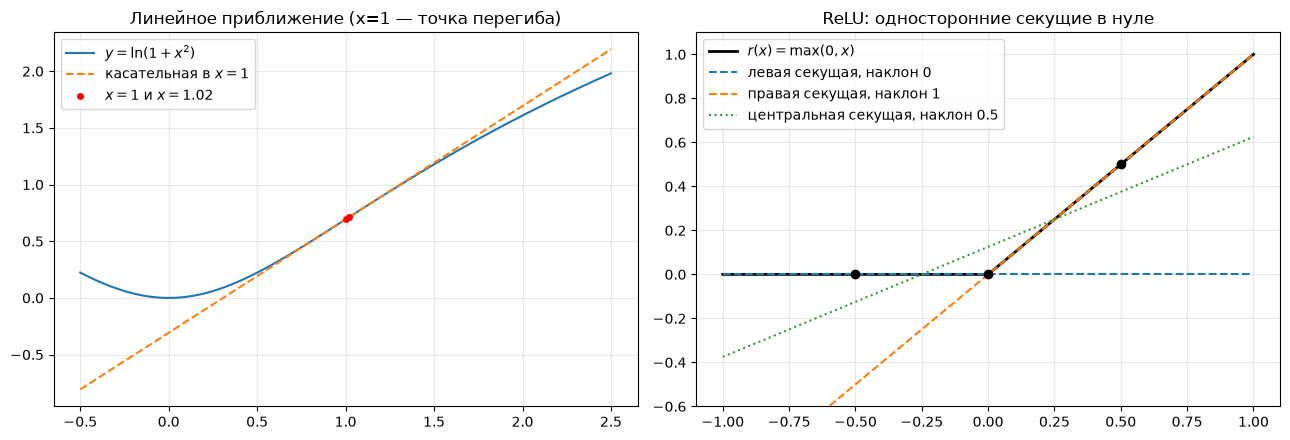

In [7]:
x0, dx = 1.0, 0.02

log_function = lambda x: np.log(1 + x**2)
log_derivative = lambda x: 2*x / (1 + x**2)   # коэффициент при dx в dy

dy_linear = log_derivative(x0) * dx
dy_exact = log_function(x0 + dx) - log_function(x0)
print(f"y'(1) = {log_derivative(x0):.6f}")
print(f"dy (линейное) = {dy_linear:.10f}")
print(f"Δy (точное)   = {dy_exact:.10f}")
print(f"|Δy - dy|     = {abs(dy_exact - dy_linear):.3e}")

relu = lambda x: np.maximum(0.0, x)
h = 1e-5
relu_left = (relu(0.0) - relu(-h)) / h
relu_right = (relu(h) - relu(0.0)) / h
relu_central = (relu(h/2) - relu(-h/2)) / h
print(f"\nReLU в нуле: левая = {relu_left}, правая = {relu_right}, центральная = {relu_central}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x_grid = np.linspace(-0.5, 2.5, 300)
axes[0].plot(x_grid, log_function(x_grid), label=r"$y=\ln(1+x^2)$")
axes[0].plot(x_grid, log_function(x0) + log_derivative(x0) * (x_grid - x0), "--",
             label="касательная в $x=1$")
axes[0].plot([x0, x0 + dx], [log_function(x0), log_function(x0 + dx)], "ro", ms=4,
             label="$x=1$ и $x=1.02$")
axes[0].set_title("Линейное приближение (x=1 — точка перегиба)")
axes[0].grid(alpha=0.3)
axes[0].legend()

s = 0.5  # большой шаг только для наглядности секущих
x_grid = np.linspace(-1, 1, 200)
axes[1].plot(x_grid, relu(x_grid), "k", lw=2, label="$r(x)=\\max(0,x)$")
axes[1].plot(x_grid, 0 * x_grid, "--", label="левая секущая, наклон 0")
axes[1].plot(x_grid, 1 * x_grid, "--", label="правая секущая, наклон 1")
axes[1].plot(x_grid, relu(s/2) / 2 + 0.5 * x_grid, ":", label="центральная секущая, наклон 0.5")
axes[1].plot([-s, 0, s], [relu(-s), 0, relu(s)], "ko")
axes[1].set_ylim(-0.6, 1.1)
axes[1].set_title("ReLU: односторонние секущие в нуле")
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Частные производные, градиент и дифференциал

### Короткая теория

Для $f:\mathbb R^n\to\mathbb R$ частная производная меняет только одну координату:

$$
\frac{\partial f}{\partial x_i}
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x)}{h}.
$$

Все частные производные собираются в градиент

$$
\nabla f(\mathbf x)=
\begin{pmatrix}
\partial f/\partial x_1\\ \vdots\\ \partial f/\partial x_n
\end{pmatrix}.
$$

При малом $\Delta\mathbf x$ полный дифференциал задаёт линейное приближение

$$
\Delta f\approx df=\nabla f(\mathbf x)^{\mathsf T}\Delta\mathbf x.
$$

См. градиент и частные производные, с. 40.

### Задание 3.1. Полный дифференциал многочлена

Источник условия: практикум, с. 140, задача 1в.

Для

$$
z=5x^3+2x^2y^4-6x+9y
$$

найдите $\partial z/\partial x$, $\partial z/\partial y$, градиент и полный дифференциал. Вычислите градиент в точке $(1,-1)$.

- **[Бумага]** При дифференцировании по одной переменной явно обозначьте другую как постоянную.
- **[Markdown]** Запишите $dz$ сначала через частные производные, затем в раскрытом виде.
- **[Python]** Проверьте обе компоненты градиента центральными покоординатными разностями.
- **[Интерпретация]** Объясните, почему коэффициент при $dx$ равен первой компоненте градиента, а коэффициент при $dy$ — второй.

#### Ваше решение

**Аналитическая часть.**

$z=5x^3+2x^2y^4-6x+9y$.

* По $x$ (считаем $y=\text{const}$, поэтому $y^4$ — постоянный множитель, а $9y$ — константа):
  $$\frac{\partial z}{\partial x}=15x^2+4xy^4-6.$$
* По $y$ (считаем $x=\text{const}$, поэтому $5x^3$ и $-6x$ — константы):
  $$\frac{\partial z}{\partial y}=8x^2y^3+9.$$

Градиент и его значение в точке $(1,-1)$:

$$
\nabla z=\begin{pmatrix}15x^2+4xy^4-6\\8x^2y^3+9\end{pmatrix},
\qquad
\nabla z(1,-1)=\begin{pmatrix}15+4-6\\-8+9\end{pmatrix}=\begin{pmatrix}13\\1\end{pmatrix}.
$$

Полный дифференциал через частные производные и в раскрытом виде:

$$
dz=\frac{\partial z}{\partial x}dx+\frac{\partial z}{\partial y}dy
=(15x^2+4xy^4-6)\,dx+(8x^2y^3+9)\,dy,
\qquad
dz\big|_{(1,-1)}=13\,dx+dy.
$$

**Численная проверка и интерпретация.**

Центральные разности по каждой координате дают $(13,\,1)$ с ошибкой порядка $10^{-10}$ (вывод ниже).

Дифференциал — это скалярное произведение $dz=\nabla z^{\mathsf T}d\mathbf x=(\nabla z)_1dx+(\nabla z)_2dy$, поэтому коэффициенты при $dx$ и $dy$ по определению являются компонентами градиента. С другой стороны, если положить $dy=0$ и двигаться только по $x$, получится $dz/dx=\partial z/\partial x$. Значит, коэффициент при $dx$ — именно частная производная по $x$, и аналогично для $y$. В точке $(1,-1)$ функция в 13 раз чувствительнее к $x$, чем к $y$.

In [8]:
def z_practice(point):
    x, y = point
    return 5*x**3 + 2*x**2*y**4 - 6*x + 9*y

def z_gradient(point):
    x, y = point
    return np.array([15*x**2 + 4*x*y**4 - 6, 8*x**2*y**3 + 9])

point = np.array([1.0, -1.0])
gradient_exact = z_gradient(point)

h = 1e-5
e_x, e_y = np.array([1.0, 0.0]), np.array([0.0, 1.0])
gradient_numeric = np.array([
    (z_practice(point + h/2*e_x) - z_practice(point - h/2*e_x)) / h,
    (z_practice(point + h/2*e_y) - z_practice(point - h/2*e_y)) / h,
])
print("Аналитический градиент:", gradient_exact)
print("Численный градиент:    ", gradient_numeric)
print("Норма ошибки:", np.linalg.norm(gradient_exact - gradient_numeric))

Аналитический градиент: [13.  1.]
Численный градиент:     [13.  1.]
Норма ошибки: 2.524701893692318e-10


### Задание 3.2. Локальная плоскость вместо касательной

Пусть

$$
f(x,y)=x^2+xy+2y^2-3x+1,
\qquad \mathbf x_0=(1,-1)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla f$, $f(\mathbf x_0)$ и линейную модель $f(\mathbf x_0+\Delta\mathbf x)$.
- **[Markdown]** Для $\Delta\mathbf x=(0.01,-0.02)^{\mathsf T}$ вычислите прогноз изменения.
- **[Python]** Сравните прогноз с точным изменением. Постройте линии уровня, точку $\mathbf x_0$, градиент и выбранное приращение.
- **[Интерпретация]** Объясните геометрическое различие между касательной к графику одной переменной и касательной плоскостью для двух переменных.

#### Ваше решение

**Аналитическая часть.**

$f(x,y)=x^2+xy+2y^2-3x+1$, $\;\mathbf x_0=(1,-1)^{\mathsf T}$.

$$
\nabla f=\begin{pmatrix}2x+y-3\\x+4y\end{pmatrix},
\qquad
\nabla f(\mathbf x_0)=\begin{pmatrix}2-1-3\\1-4\end{pmatrix}=\begin{pmatrix}-2\\-3\end{pmatrix},
\qquad
f(\mathbf x_0)=1-1+2-3+1=0.
$$

Линейная модель (касательная плоскость):

$$
f(\mathbf x_0+\Delta\mathbf x)\approx f(\mathbf x_0)+\nabla f(\mathbf x_0)^{\mathsf T}\Delta\mathbf x
=-2\,\Delta x-3\,\Delta y .
$$

Для $\Delta\mathbf x=(0.01,-0.02)^{\mathsf T}$ прогноз изменения: $\;df=-2\cdot0.01-3\cdot(-0.02)=-0.02+0.06=0.04$.

**Численная проверка и интерпретация.**

Точное изменение равно $0.0407$, прогноз — $0.04$. Разница $0.0007$ (≈1.7 %) — это квадратичный член. Функция $f$ квадратичная с гессианом $\mathbf H=\begin{pmatrix}2&1\\1&4\end{pmatrix}$, поэтому
$\Delta f=\nabla f^{\mathsf T}\Delta\mathbf x+\tfrac12\Delta\mathbf x^{\mathsf T}\mathbf H\Delta\mathbf x$ выполняется точно, и $\tfrac12(2\cdot10^{-4}-4\cdot10^{-4}+16\cdot10^{-4})=7\cdot10^{-4}$.

На графике градиент $(-2,-3)$ перпендикулярен линии уровня через $\mathbf x_0$ и смотрит в сторону роста $f$. Угол между $\Delta\mathbf x$ и градиентом острый ($\nabla f^{\mathsf T}\Delta\mathbf x=0.04>0$), поэтому функция немного растёт.

**Геометрия.** Для функции одной переменной график — кривая в плоскости, и её линейная модель — *касательная прямая* с одним наклоном $f'(x_0)$. Для двух переменных график — поверхность в $\mathbb R^3$, и линейная модель — *касательная плоскость* $z=f(\mathbf x_0)+\nabla f^{\mathsf T}(\mathbf x-\mathbf x_0)$. Её задают два наклона, то есть компоненты градиента. Любое направление даёт свою касательную прямую, и все они лежат в этой плоскости.

f(x0) = 0.0
grad f(x0) = [-2. -3.]
Прогноз df = 0.040000, точное Δf = 0.040700, разница = 0.000700
1/2 Δ^T H Δ = 0.0007000000000000001


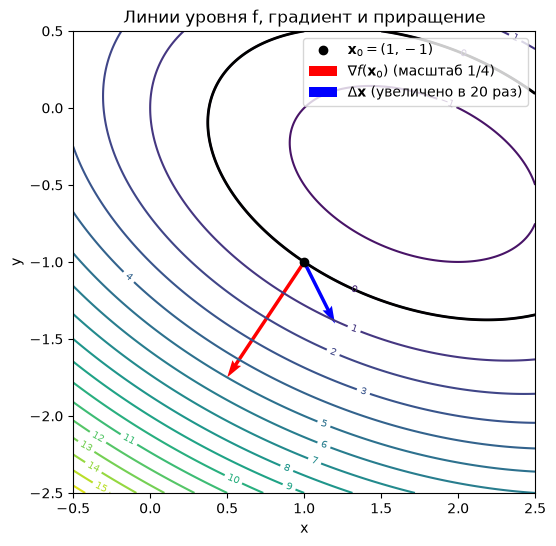

In [9]:
def f_quadratic(point):
    x, y = point
    return x**2 + x*y + 2*y**2 - 3*x + 1

def f_quadratic_gradient(point):
    x, y = point
    return np.array([2*x + y - 3, x + 4*y])

x_base = np.array([1.0, -1.0])
delta = np.array([0.01, -0.02])

gradient_base = f_quadratic_gradient(x_base)
linear_change = gradient_base @ delta
exact_change = f_quadratic(x_base + delta) - f_quadratic(x_base)
H_quadratic = np.array([[2.0, 1.0], [1.0, 4.0]])
print("f(x0) =", f_quadratic(x_base))
print("grad f(x0) =", gradient_base)
print(f"Прогноз df = {linear_change:.6f}, точное Δf = {exact_change:.6f}, "
      f"разница = {exact_change - linear_change:.6f}")
print("1/2 Δ^T H Δ =", 0.5 * delta @ H_quadratic @ delta)

xs, ys = np.meshgrid(np.linspace(-0.5, 2.5, 200), np.linspace(-2.5, 0.5, 200))
values = f_quadratic((xs, ys))
fig, ax = plt.subplots(figsize=(7, 6))
contours = ax.contour(xs, ys, values, levels=20, cmap="viridis")
ax.clabel(contours, fontsize=7)
ax.contour(xs, ys, values, levels=[f_quadratic(x_base)], colors="k", linewidths=2)
ax.plot(*x_base, "ko", label="$\\mathbf{x}_0=(1,-1)$")
ax.quiver(*x_base, *gradient_base, angles="xy", scale_units="xy", scale=4, color="red",
          label="$\\nabla f(\\mathbf{x}_0)$ (масштаб 1/4)")
ax.quiver(*x_base, *(delta * 20), angles="xy", scale_units="xy", scale=1, color="blue",
          label="$\\Delta\\mathbf{x}$ (увеличено в 20 раз)")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Линии уровня f, градиент и приращение")
ax.legend(loc="upper right")
plt.show()

### Задание 3.3. Численный градиент по координатам

- **[Бумага]** Запишите центральную разность для каждой компоненты $\nabla f(\mathbf x)$ через $\mathbf e_i$.
- **[Python]** Реализуйте функцию `central_gradient(f, x, h)`, не зашивая число координат. Проверьте её на функции из задания 3.2 для нескольких $h$.
- **[Markdown]** Сопоставьте аналитический и численный векторы и укажите норму ошибки.
- **[Интерпретация]** Посчитайте число обращений к $f$ для центральной разности в $n$ измерениях и объясните, почему цена растёт с размерностью.

#### Ваше решение

**Аналитическая часть.**

Для каждой координаты $i=1,\dots,n$ меняем только её, сдвигаясь вдоль базисного вектора $\mathbf e_i$:

$$
\big(\nabla f(\mathbf x)\big)_i=\frac{\partial f}{\partial x_i}(\mathbf x)\approx
\frac{f\!\left(\mathbf x+\tfrac h2\mathbf e_i\right)-f\!\left(\mathbf x-\tfrac h2\mathbf e_i\right)}{h}.
$$

Функция `central_gradient` проходит по всем элементам массива по очереди (через `.flat`), поэтому число координат в ней не зашито. Она работает и для векторов, и для матриц, и я её дальше использую в заданиях 5, 7 и 8.

**Численная проверка и интерпретация.**

Аналитический градиент $(-2,-3)$ и численный совпадают. Нормы ошибки для $h=10^{-1},10^{-3},10^{-5},10^{-7},10^{-9}$ равны примерно $7\cdot10^{-15},\ 6\cdot10^{-13},\ 5\cdot10^{-11},\ 5\cdot10^{-9},\ 3\cdot10^{-7}$ (таблица ниже).

Ошибка здесь растёт при уменьшении $h$. Так получается потому, что функция квадратичная, третья производная у неё равна нулю, и центральная разность для неё точная при любом $h$. Остаётся только ошибка округления, а она больше при маленьком шаге.

**Стоимость.** На каждую координату нужно 2 вызова $f$, значит всего $2n$. При $n=2$ это 4 вызова, но если параметров, например, миллион, то нужно уже 2 миллиона вызовов на один градиент. Поэтому конечные разности подходят для проверки формул на маленьких задачах, а не для обычного счёта.

In [10]:
def central_gradient(function, point, h=1e-5):
    # сдвигаем по очереди каждый элемент (через .flat, чтобы работало и для матриц)
    point = np.asarray(point, dtype=float)
    gradient = np.zeros_like(point)
    for i in range(point.size):
        e_i = np.zeros_like(point)
        e_i.flat[i] = 1.0
        gradient.flat[i] = (function(point + h/2 * e_i) - function(point - h/2 * e_i)) / h
    return gradient

gradient_exact = f_quadratic_gradient(x_base)
print("Аналитический градиент:", gradient_exact)
print(f"{'h':>8} | численный градиент              | норма ошибки")
for h in [1e-1, 1e-3, 1e-5, 1e-7, 1e-9]:
    g = central_gradient(f_quadratic, x_base, h)
    print(f"{h:8.0e} | {np.array2string(g, precision=12):32s} | {np.linalg.norm(g - gradient_exact):.2e}")
n_dim = x_base.size
print(f"\nВызовов f на один градиент: 2n = {2 * n_dim} (n = {n_dim}); для n = 10^6: {2 * 10**6:.0e}")

Аналитический градиент: [-2. -3.]
       h | численный градиент              | норма ошибки
   1e-01 | [-2. -3.]                        | 6.76e-15
   1e-03 | [-2.             -2.999999999999] | 5.96e-13
   1e-05 | [-2.000000000035 -3.000000000042] | 5.48e-11
   1e-07 | [-2.000000001168 -2.99999999509 ] | 5.05e-09
   1e-09 | [-2.000000165481 -3.000000248221] | 2.98e-07

Вызовов f на один градиент: 2n = 4 (n = 2); для n = 10^6: 2e+06


## 4. Производная по направлению и полная производная

### Короткая теория

Производная по направлению $\mathbf v$ равна

$$
D_{\mathbf v}f(\mathbf x)
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf v)-f(\mathbf x)}{h}
=\nabla f(\mathbf x)^{\mathsf T}\mathbf v.
$$

При зависимых аргументах используется полная производная:

$$
\frac{dF}{dt}
=\frac{\partial F}{\partial t}
+\frac{\partial F}{\partial x}\frac{dx}{dt}
+\frac{\partial F}{\partial y}\frac{dy}{dt}.
$$

Оба оператора приведены в теории, с. 40.

### Задание 4.1. Изменение вдоль выбранного направления

Используйте функцию и точку из задания 3.2, а также единичный вектор

$$
\mathbf v=\frac15(3,4)^{\mathsf T}.
$$

- **[Бумага]** Вычислите $D_{\mathbf v}f(\mathbf x_0)$ и определите, возрастает или убывает функция при движении вдоль $\mathbf v$.
- **[Markdown]** Найдите единичные направления максимального роста и максимального убывания и соответствующие скорости.
- **[Python]** Проверьте направленную производную центральной разностью, меняя только один скаляр $h$.
- **[Интерпретация]** Объясните, почему направление необходимо нормировать, если требуется сравнивать именно скорость на единицу пути.

#### Ваше решение

**Аналитическая часть.**

Из задания 3.2: $\nabla f(\mathbf x_0)=(-2,-3)^{\mathsf T}$, $\;\mathbf v=(0.6,\,0.8)^{\mathsf T}$, $\;\lVert\mathbf v\rVert=1$.

$$
D_{\mathbf v}f(\mathbf x_0)=\nabla f(\mathbf x_0)^{\mathsf T}\mathbf v=(-2)(0.6)+(-3)(0.8)=-1.2-2.4=-3.6<0,
$$

поэтому при движении вдоль $\mathbf v$ функция **убывает**.

**Экстремальные направления.** По неравенству Коши–Буняковского $|\nabla f^{\mathsf T}\mathbf v|\le\lVert\nabla f\rVert\,\lVert\mathbf v\rVert$, причём равенство достигается при $\mathbf v\parallel\nabla f$. Здесь $\lVert\nabla f(\mathbf x_0)\rVert=\sqrt{4+9}=\sqrt{13}\approx3.6056$.

* Максимальный рост: $\;\mathbf u_+=\dfrac{\nabla f}{\lVert\nabla f\rVert}=\dfrac{(-2,-3)}{\sqrt{13}}\approx(-0.5547,\,-0.8321)$, скорость $+\sqrt{13}\approx+3.6056$.
* Максимальное убывание: $\;\mathbf u_-=-\mathbf u_+=\dfrac{(2,3)}{\sqrt{13}}\approx(0.5547,\,0.8321)$, скорость $-\sqrt{13}\approx-3.6056$.

**Численная проверка и интерпретация.**

Центральная разность вдоль $\mathbf v$ меняет только один скаляр $h$: $\;\dfrac{f(\mathbf x_0+\tfrac h2\mathbf v)-f(\mathbf x_0-\tfrac h2\mathbf v)}{h}\approx-3.6$, ошибка порядка $10^{-11}$.

Скорость вдоль $\mathbf v$ ($-3.6$) очень близка к максимально возможной скорости убывания ($-3.6056$): угол между $\mathbf v$ и $\mathbf u_-$ около $3.2^\circ$.

**Зачем нормировать.** $D_{\mathbf v}f$ линейна по $\mathbf v$: $D_{c\mathbf v}f=c\,D_{\mathbf v}f$. Для ненормированного $\mathbf w=(3,4)=5\mathbf v$ получим $-18$. Функция при этом не убывает в 5 раз быстрее: просто за один «шаг» $h$ мы проходим путь $5h$. Чтобы сравнивать скорость изменения на единицу пройденного расстояния, все направления берут единичной длины.

In [11]:
x_base = np.array([1.0, -1.0])
v_direction = np.array([3.0, 4.0]) / 5.0

gradient_base = f_quadratic_gradient(x_base)
directional_exact = gradient_base @ v_direction

grad_norm = np.linalg.norm(gradient_base)
ascent_direction = gradient_base / grad_norm
descent_direction = -ascent_direction

h = 1e-5
directional_numeric = (f_quadratic(x_base + h/2 * v_direction)
                       - f_quadratic(x_base - h/2 * v_direction)) / h

print(f"D_v f (аналитически) = {directional_exact:.6f}")
print(f"D_v f (центр. разность) = {directional_numeric:.10f}, ошибка {abs(directional_numeric - directional_exact):.1e}")
print(f"Макс. рост:     направление {ascent_direction}, скорость {+grad_norm:.6f}")
print(f"Макс. убывание: направление {descent_direction}, скорость {-grad_norm:.6f}")
angle = np.degrees(np.arccos(v_direction @ descent_direction))
print(f"Угол между v и направлением наискорейшего убывания: {angle:.2f}°")
print("Ненормированное w = (3,4):", gradient_base @ np.array([3.0, 4.0]), "= 5 * D_v f")

D_v f (аналитически) = -3.600000
D_v f (центр. разность) = -3.6000000000, ошибка 3.0e-11
Макс. рост:     направление [-0.5547  -0.83205], скорость 3.605551
Макс. убывание: направление [0.5547  0.83205], скорость -3.605551
Угол между v и направлением наискорейшего убывания: 3.18°
Ненормированное w = (3,4): -18.0 = 5 * D_v f


### Задание 4.2. Все пути влияния переменной

Пусть

$$
F(t,x,y)=tx+x^2+xy+2y^2,
\qquad x(t)=t,
\qquad y(t)=t^2.
$$

- **[Бумага]** Найдите $dF/dt$ двумя способами: сначала подставьте $x(t),y(t)$, затем примените формулу полной производной.
- **[Markdown]** В формуле полной производной подпишите прямой путь $t\to F$ и косвенные пути $t\to x\to F$, $t\to y\to F$.
- **[Python]** Сравните оба выражения и центральную разность при $t=1$.
- **[Интерпретация]** Объясните, почему пропуск одного пути зависимости даёт неполную производную.

#### Ваше решение

**Аналитическая часть.**

$F(t,x,y)=tx+x^2+xy+2y^2$, $\;x(t)=t$, $\;y(t)=t^2$.

**Способ 1: подстановка.** $\;F(t)=t\cdot t+t^2+t\cdot t^2+2t^4=2t^2+t^3+2t^4$, отсюда

$$
\frac{dF}{dt}=4t+3t^2+8t^3,\qquad \frac{dF}{dt}\Big|_{t=1}=4+3+8=15.
$$

**Способ 2: полная производная.**
$\dfrac{\partial F}{\partial t}=x,\;\; \dfrac{\partial F}{\partial x}=t+2x+y,\;\; \dfrac{\partial F}{\partial y}=x+4y,\;\; \dfrac{dx}{dt}=1,\;\; \dfrac{dy}{dt}=2t.$

$$
\frac{dF}{dt}
=\underbrace{\frac{\partial F}{\partial t}}_{\text{прямой путь }t\to F}
+\underbrace{\frac{\partial F}{\partial x}\frac{dx}{dt}}_{\text{путь }t\to x\to F}
+\underbrace{\frac{\partial F}{\partial y}\frac{dy}{dt}}_{\text{путь }t\to y\to F}
=x+(t+2x+y)\cdot1+(x+4y)\cdot2t .
$$

После подстановки $x=t,\ y=t^2$: $\;t+(3t+t^2)+(t+4t^2)2t=4t+3t^2+8t^3$, что совпадает со способом 1.

При $t=1$ ($x=1,\ y=1$): $\;1+4+10=15$.

**Численная проверка и интерпретация.**

Оба выражения и центральная разность $F(t)$ при $t=1$ дают $15$ (вывод ниже). Вклады путей: прямой $1$, через $x$ — $4$, через $y$ — $10$.

$t$ влияет на $F$ тремя путями, и полная производная — это сумма вкладов всех трёх. Если забыть путь через $y$, получится $5$ вместо $15$, а без прямого пути — $14$. Одна частная производная $\partial F/\partial t=1$ показывает изменение $F$ только при фиксированных $x$ и $y$, а здесь они меняются вместе с $t$.

In [12]:
def F_total(t, x, y):
    return t*x + x**2 + x*y + 2*y**2

def dF_substituted(t):
    # F(t) = 2t^2 + t^3 + 2t^4
    return 4*t + 3*t**2 + 8*t**3

def dF_total_derivative(t):
    x, y = t, t**2
    dx_dt, dy_dt = 1.0, 2*t
    direct = x                       # ∂F/∂t
    via_x = (t + 2*x + y) * dx_dt    # ∂F/∂x · dx/dt
    via_y = (x + 4*y) * dy_dt        # ∂F/∂y · dy/dt
    return direct + via_x + via_y, (direct, via_x, via_y)

t0, h = 1.0, 1e-5
F_of_t = lambda t: F_total(t, t, t**2)
numeric = (F_of_t(t0 + h/2) - F_of_t(t0 - h/2)) / h
total, (direct, via_x, via_y) = dF_total_derivative(t0)

print("После подстановки:   dF/dt =", dF_substituted(t0))
print("Полная производная:  dF/dt =", total)
print(f"Центральная разность: dF/dt = {numeric:.10f}")
print(f"Вклады путей: t→F = {direct}, t→x→F = {via_x}, t→y→F = {via_y}")
print("Без пути через y:", direct + via_x, "| без прямого пути:", via_x + via_y)

После подстановки:   dF/dt = 15.0
Полная производная:  dF/dt = 15.0
Центральная разность: dF/dt = 15.0000000003
Вклады путей: t→F = 1.0, t→x→F = 4.0, t→y→F = 10.0
Без пути через y: 5.0 | без прямого пути: 14.0


## 5. Якобиан, JVP, VJP и цепное правило

### Короткая теория

Для $\mathbf f:\mathbb R^n\to\mathbb R^m$ якобиан имеет размер $m\times n$:

$$
\mathbf J_{\mathbf f}(\mathbf x)=
\begin{pmatrix}
\nabla f_1(\mathbf x)^{\mathsf T}\\
\vdots\\
\nabla f_m(\mathbf x)^{\mathsf T}
\end{pmatrix}.
$$

Произведение $\mathbf J\mathbf v$ называется JVP, а $\mathbf u^{\mathsf T}\mathbf J$ — VJP. Для композиции $\mathbf h=\mathbf g\circ\mathbf f$

$$
\mathbf J_{\mathbf h}(\mathbf x)
=\mathbf J_{\mathbf g}(\mathbf f(\mathbf x))\mathbf J_{\mathbf f}(\mathbf x).
$$

См. якобиан, JVP, VJP и цепное правило, с. 41.

### Задание 5.1. Якобиан векторной функции

Рассмотрите

$$
\mathbf f(x_1,x_2)=
\begin{pmatrix}
x_1^2+x_2\\
e^{x_1-x_2}\\
x_1x_2
\end{pmatrix}.
$$

- **[Бумага]** Найдите все шесть частных производных и соберите якобиан.
- **[Markdown]** Укажите размерности входа, выхода и якобиана. Вычислите $\mathbf f$ и $\mathbf J_{\mathbf f}$ в точке $\mathbf x_*=(1,0)^{\mathsf T}$.
- **[Python]** Реализуйте `vector_function` и `jacobian_exact`, проверьте строки якобиана покоординатными разностями.
- **[Интерпретация]** Объясните, что означает элемент $J_{ij}$ и почему градиенты компонент выхода расположены по строкам.

#### Ваше решение

**Аналитическая часть.**

$\mathbf f:\mathbb R^2\to\mathbb R^3$, вход $\mathbf x=(x_1,x_2)^{\mathsf T}\in\mathbb R^2$, выход $\mathbf f(\mathbf x)\in\mathbb R^3$, поэтому $\mathbf J_{\mathbf f}\in\mathbb R^{3\times2}$.

Шесть частных производных:

| | $\partial/\partial x_1$ | $\partial/\partial x_2$ |
|---|---|---|
| $f_1=x_1^2+x_2$ | $2x_1$ | $1$ |
| $f_2=e^{x_1-x_2}$ | $e^{x_1-x_2}$ | $-e^{x_1-x_2}$ |
| $f_3=x_1x_2$ | $x_2$ | $x_1$ |

$$
\mathbf J_{\mathbf f}(\mathbf x)=\begin{pmatrix}2x_1&1\\e^{x_1-x_2}&-e^{x_1-x_2}\\x_2&x_1\end{pmatrix}.
$$

В точке $\mathbf x_*=(1,0)^{\mathsf T}$:

$$
\mathbf f(\mathbf x_*)=\begin{pmatrix}1\\e\\0\end{pmatrix},\qquad
\mathbf J_{\mathbf f}(\mathbf x_*)=\begin{pmatrix}2&1\\e&-e\\0&1\end{pmatrix}\approx\begin{pmatrix}2&1\\2.71828&-2.71828\\0&1\end{pmatrix}.
$$

**Численная проверка и интерпретация.**

Покоординатные разности дают столбцы якобиана: сдвиг по $x_j$ меняет все выходы сразу. Из них собирается матрица, и её строки совпадают с аналитическими с ошибкой порядка $10^{-11}$ (вывод ниже).

Элемент $J_{ij}=\partial f_i/\partial x_j$ показывает, насколько изменится $i$-й выход при единичном изменении $j$-го входа. Например, $J_{22}=-e$: рост $x_2$ уменьшает $f_2$ со скоростью $e$.

$i$-я строка якобиана — это транспонированный градиент $\nabla f_i^{\mathsf T}$. Так удобно, потому что тогда $d\mathbf f=\mathbf J\,d\mathbf x$: строка $i$, умноженная на $d\mathbf x$, даёт $df_i=\nabla f_i^{\mathsf T}d\mathbf x$, как в задании 3.1. Строк столько же, сколько выходов (3), а столбцов — сколько входов (2).

In [13]:
def vector_function(point):
    x1, x2 = point
    return np.array([x1**2 + x2, np.exp(x1 - x2), x1*x2])

x_star = np.array([1.0, 0.0])

def jacobian_exact(point):
    x1, x2 = point
    ex = np.exp(x1 - x2)
    return np.array([
        [2*x1, 1.0],
        [ex,   -ex],
        [x2,   x1],
    ])

h = 1e-5
J_star = jacobian_exact(x_star)
J_numeric = np.zeros((3, 2))
for j in range(2):                       # сдвиг по x_j даёт j-й столбец
    e_j = np.zeros(2)
    e_j[j] = 1.0
    J_numeric[:, j] = (vector_function(x_star + h/2*e_j) - vector_function(x_star - h/2*e_j)) / h

print("f(x*) =", vector_function(x_star))
print("J (аналитически):\n", J_star, "\nформа", J_star.shape)
for i in range(3):
    print(f"строка {i+1}: аналит. {J_star[i]}, числ. {J_numeric[i]}, ошибка {np.linalg.norm(J_star[i] - J_numeric[i]):.1e}")

f(x*) = [1.       2.718282 0.      ]
J (аналитически):
 [[ 2.        1.      ]
 [ 2.718282 -2.718282]
 [ 0.        1.      ]] 
форма (3, 2)
строка 1: аналит. [2. 1.], числ. [2. 1.], ошибка 1.5e-11
строка 2: аналит. [ 2.718282 -2.718282], числ. [ 2.718282 -2.718282], ошибка 8.3e-11
строка 3: аналит. [0. 1.], числ. [0. 1.], ошибка 0.0e+00


### Задание 5.2. JVP без полного численного якобиана

Пусть $\mathbf v=(1,-2)^{\mathsf T}$.

- **[Бумага]** Вычислите $\mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v$.
- **[Markdown]** Запишите центральную аппроксимацию

  $$
  \mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v
  \approx
  \frac{\mathbf f(\mathbf x_*+h\mathbf v/2)-
  \mathbf f(\mathbf x_*-h\mathbf v/2)}{h}.
  $$

- **[Python]** Сравните точное и численное JVP для разных $h$, постройте график нормы ошибки.
- **[Интерпретация]** Объясните, почему для численного JVP нужны два обращения к $\mathbf f$ независимо от числа входных координат.

#### Ваше решение

**Аналитическая часть.**

$$
\mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v=
\begin{pmatrix}2&1\\e&-e\\0&1\end{pmatrix}\begin{pmatrix}1\\-2\end{pmatrix}
=\begin{pmatrix}2-2\\e+2e\\-2\end{pmatrix}
=\begin{pmatrix}0\\3e\\-2\end{pmatrix}\approx\begin{pmatrix}0\\8.154845\\-2\end{pmatrix}.
$$

Размерности: $(3\times2)\cdot(2\times1)=3\times1$. JVP живёт в пространстве *выходов*: это скорость изменения $\mathbf f$ при движении входа вдоль $\mathbf v$.

Центральная аппроксимация:

$$
\mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v\approx
\frac{\mathbf f(\mathbf x_*+h\mathbf v/2)-\mathbf f(\mathbf x_*-h\mathbf v/2)}{h}.
$$

**Численная проверка и интерпретация.**

Норма ошибки падает как $h^2$: $3.1\cdot10^{-2}$ при $h=10^{-1}$, $3.1\cdot10^{-4}$ при $10^{-2}$, $3.1\cdot10^{-6}$ при $10^{-3}$, $3.1\cdot10^{-8}$ при $10^{-4}$. Минимум $\approx3\cdot10^{-10}$ достигается при $h\approx10^{-5}$–$10^{-6}$, а при меньших $h$ снова растёт из-за округления ($\approx4\cdot10^{-4}$ при $h=10^{-12}$). Картина та же, что в задании 2.1.

**Почему два вызова.** $\mathbf J\mathbf v$ — это производная $\mathbf f$ по направлению $\mathbf v$. Мы двигаемся только вдоль одной прямой $\mathbf x_*+s\mathbf v$, и для разности хватает двух точек на ней, сколько бы координат ни было у $\mathbf x$. Для полного якобиана пришлось бы делать по 2 вызова на каждую координату, то есть $2n$.

Точный JVP J v = [ 0.        8.154845 -2.      ]  форма (3,)
h = 1e-01: численный JVP = [ 0.          8.18546058 -2.        ], ошибка 3.06e-02
h = 1e-02: численный JVP = [-0.         8.1551513 -2.       ], ошибка 3.06e-04
h = 1e-03: численный JVP = [ 0.          8.15484854 -2.        ], ошибка 3.06e-06
h = 1e-04: численный JVP = [ 0.          8.15484552 -2.        ], ошибка 3.06e-08
h = 1e-05: численный JVP = [ 0.          8.15484549 -2.        ], ошибка 3.53e-10
h = 1e-06: численный JVP = [ 0.          8.15484549 -2.        ], ошибка 2.83e-10
h = 1e-07: численный JVP = [-0.          8.15484548 -2.        ], ошибка 3.02e-09
h = 1e-08: численный JVP = [-0.00000001  8.15484547 -2.        ], ошибка 2.27e-08
h = 1e-09: численный JVP = [ 0.00000011  8.15484613 -2.        ], ошибка 6.56e-07
h = 1e-10: численный JVP = [ 0.          8.15484569 -2.        ], ошибка 2.02e-07
h = 1e-11: численный JVP = [ 0.          8.15485457 -2.        ], ошибка 9.08e-06
h = 1e-12: численный JVP = [ 0.00011102 

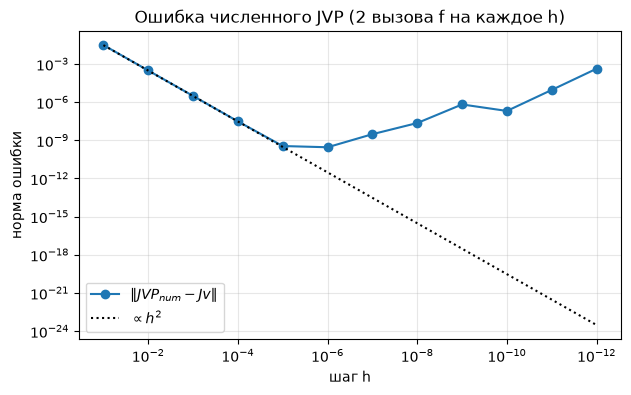

In [14]:
v_jvp = np.array([1.0, -2.0])

exact_jvp = jacobian_exact(x_star) @ v_jvp
print("Точный JVP J v =", exact_jvp, " форма", exact_jvp.shape)

h_list = np.logspace(-1, -12, 12)
jvp_errors = []
for h in h_list:
    numeric_jvp = (vector_function(x_star + h*v_jvp/2) - vector_function(x_star - h*v_jvp/2)) / h
    jvp_errors.append(np.linalg.norm(numeric_jvp - exact_jvp))
    print(f"h = {h:.0e}: численный JVP = {np.array2string(numeric_jvp, precision=8)}, ошибка {jvp_errors[-1]:.2e}")

plt.figure(figsize=(7, 4))
plt.loglog(h_list, jvp_errors, "o-", label="$\\|JVP_{num} - J v\\|$")
plt.loglog(h_list, 3 * h_list**2, "k:", label="$\\propto h^2$")
plt.gca().invert_xaxis()
plt.xlabel("шаг h")
plt.ylabel("норма ошибки")
plt.title("Ошибка численного JVP (2 вызова f на каждое h)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Задание 5.3. VJP и производная композиции

Сначала для $\mathbf u=(1,2,-1)^{\mathsf T}$ вычислите $\mathbf u^{\mathsf T}\mathbf J_{\mathbf f}(\mathbf x_*)$. Затем определите

$$
g(\mathbf z)=\frac12\lVert\mathbf z-\mathbf c\rVert_2^2,
\qquad
\mathbf c=(0,1,1)^{\mathsf T},
\qquad
h(\mathbf x)=g(\mathbf f(\mathbf x)).
$$

- **[Бумага]** Найдите $\nabla_{\mathbf z}g$ и $\nabla_{\mathbf x}h=\mathbf J_{\mathbf f}^{\mathsf T}\nabla_{\mathbf z}g$ в точке $\mathbf x_*$.
- **[Markdown]** Проверьте размерности каждого множителя и результата цепного правила.
- **[Python]** Сравните аналитический градиент композиции с `central_gradient`.
- **[Интерпретация]** Объясните, как VJP передаёт чувствительность одного скалярного результата ко всем входным координатам.

#### Ваше решение

**Аналитическая часть.**

**VJP.** Для $\mathbf u=(1,2,-1)^{\mathsf T}$:

$$
\mathbf u^{\mathsf T}\mathbf J_{\mathbf f}(\mathbf x_*)=(1,\;2,\;-1)\begin{pmatrix}2&1\\e&-e\\0&1\end{pmatrix}
=(2+2e+0,\;\;1-2e-1)=(2+2e,\;-2e)\approx(7.436564,\;-5.436564).
$$

Размеры: $(1\times3)\cdot(3\times2)=1\times2$. VJP живёт в пространстве *входов*.

**Композиция.** $g(\mathbf z)=\tfrac12\lVert\mathbf z-\mathbf c\rVert_2^2=\tfrac12\sum_i(z_i-c_i)^2$, поэтому $\;\dfrac{\partial g}{\partial z_i}=z_i-c_i$ и $\nabla_{\mathbf z}g=\mathbf z-\mathbf c$.

В точке $\mathbf x_*$: $\;\mathbf z=\mathbf f(\mathbf x_*)=(1,e,0)^{\mathsf T}$, $\;\nabla_{\mathbf z}g=(1,\;e-1,\;-1)^{\mathsf T}\approx(1,\,1.718282,\,-1)^{\mathsf T}$.

$$
\nabla_{\mathbf x}h=\mathbf J_{\mathbf f}^{\mathsf T}\nabla_{\mathbf z}g
=\begin{pmatrix}2&e&0\\1&-e&1\end{pmatrix}\begin{pmatrix}1\\e-1\\-1\end{pmatrix}
=\begin{pmatrix}2+e(e-1)\\1-e(e-1)-1\end{pmatrix}
=\begin{pmatrix}2+e^2-e\\e-e^2\end{pmatrix}\approx\begin{pmatrix}6.670774\\-4.670774\end{pmatrix}.
$$

**Размерности цепного правила:** $\;\underbrace{\nabla_{\mathbf x}h}_{2\times1}=\underbrace{\mathbf J_{\mathbf f}^{\mathsf T}}_{2\times3}\,\underbrace{\nabla_{\mathbf z}g}_{3\times1}$. Эквивалентно, в форме якобианов: $\underbrace{\mathbf J_h}_{1\times2}=\underbrace{\mathbf J_g}_{1\times3}\underbrace{\mathbf J_{\mathbf f}}_{3\times2}$. Это и есть VJP с $\mathbf u=\nabla_{\mathbf z}g$.

**Численная проверка и интерпретация.**

`central_gradient` от $h(\mathbf x)$ даёт $(6.670774,\,-4.670774)$ с ошибкой порядка $10^{-10}$. Численный VJP (градиент скаляра $\mathbf u^{\mathsf T}\mathbf f(\mathbf x)$) совпадает с $(2+2e,\,-2e)$ (вывод ниже).

Компонента $(\mathbf u^{\mathsf T}\mathbf J)_j=\sum_i u_i\,\partial f_i/\partial x_j$ собирает влияние входа $x_j$ на все выходы с весами $u_i$. Если взять $\mathbf u=\nabla_{\mathbf z}g$, то есть чувствительность $h$ к каждому выходу $\mathbf f$, то одно такое произведение сразу даёт градиент $h$ по всем входам. Чувствительность скалярного результата как бы передаётся назад через $\mathbf f$ ко всем $x_j$.

In [15]:
u_vjp = np.array([1.0, 2.0, -1.0])
c_target = np.array([0.0, 1.0, 1.0])

J_star = jacobian_exact(x_star)
vjp_exact = u_vjp @ J_star
vjp_numeric = central_gradient(lambda x: u_vjp @ vector_function(x), x_star)
print("u^T J (аналитически):", vjp_exact, " форма", vjp_exact.shape)
print("u^T J (численно):    ", vjp_numeric)

def h_composite(point):
    z = vector_function(point)
    return 0.5 * np.sum((z - c_target)**2)

def h_composite_gradient(point):
    grad_z = vector_function(point) - c_target       # ∇_z g, форма (3,)
    return jacobian_exact(point).T @ grad_z          # (2,3) @ (3,) -> (2,)

grad_h_exact = h_composite_gradient(x_star)
grad_h_numeric = central_gradient(h_composite, x_star)
print("\n∇_z g(f(x*)) =", vector_function(x_star) - c_target)
print("∇h (цепное правило):", grad_h_exact)
print("∇h (central_gradient):", grad_h_numeric)
print("Норма ошибки:", np.linalg.norm(grad_h_exact - grad_h_numeric))

u^T J (аналитически): [ 7.436564 -5.436564]  форма (2,)
u^T J (численно):     [ 7.436564 -5.436564]

∇_z g(f(x*)) = [ 1.        1.718282 -1.      ]
∇h (цепное правило): [ 6.670774 -4.670774]
∇h (central_gradient): [ 6.670774 -4.670774]
Норма ошибки: 3.1474709963359883e-10


## 6. Гессиан и кривизна

### Короткая теория

Гессиан дважды дифференцируемой функции $f:\mathbb R^n\to\mathbb R$ — якобиан градиента:

$$
\mathbf H_f(\mathbf x)=\nabla^2f(\mathbf x)
=\begin{pmatrix}
\frac{\partial^2f}{\partial x_1^2}&\cdots&\frac{\partial^2f}{\partial x_1\partial x_n}\\
\vdots&\ddots&\vdots\\
\frac{\partial^2f}{\partial x_n\partial x_1}&\cdots&\frac{\partial^2f}{\partial x_n^2}
\end{pmatrix}.
$$

В стационарной точке положительно определённый гессиан указывает на локальный минимум, отрицательно определённый — на максимум, а неопределённый — на седловую точку. См. гессиан, с. 41–42, положительно определённые матрицы, с. 13 и геометрию квадратичных форм, с. 27.

### Задание 6.1. Положительная кривизна и минимум

Источник условия: практикум, с. 142, задача 1.

Исследуйте на экстремум

$$
z=2x^2+y^2+x-3y+2xy.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, его определитель и собственные значения.
- **[Markdown]** Классифицируйте точку и вычислите значение функции.
- **[Python]** Проверьте решение, постройте линии уровня и отметьте стационарную точку.
- **[Интерпретация]** Свяжите положительные собственные значения с ростом функции во всех достаточно малых направлениях от минимума.

#### Ваше решение

**Аналитическая часть.**

$z=2x^2+y^2+x-3y+2xy$.

Условие стационарности:

$$
\begin{cases}
z_x=4x+2y+1=0,\\
z_y=2x+2y-3=0.
\end{cases}
$$

Вычтем второе уравнение из первого: $2x+4=0$, откуда $x=-2$ и $y=\frac{3-2x}{2}=3.5$. Стационарная точка: $\mathbf x_*=(-2,\;3.5)$.

Гессиан (постоянный, так как функция квадратичная):

$$
\mathbf H=\begin{pmatrix}z_{xx}&z_{xy}\\z_{yx}&z_{yy}\end{pmatrix}=\begin{pmatrix}4&2\\2&2\end{pmatrix},\qquad
\det\mathbf H=8-4=4>0,\qquad z_{xx}=4>0.
$$

Собственные значения: $\lambda^2-\operatorname{tr}\mathbf H\,\lambda+\det\mathbf H=\lambda^2-6\lambda+4=0$, откуда $\lambda_{1,2}=3\mp\sqrt5\approx0.764,\;5.236$.

**Классификация.** Оба собственных значения положительны (то же даёт критерий Сильвестра: $4>0$, $\det=4>0$). Гессиан положительно определён, поэтому $\mathbf x_*$ — **локальный (и глобальный) минимум**.

$z_{\min}=z(-2,3.5)=8+12.25-2-10.5-14=-6.25$.

**Численная проверка и интерпретация.**

`np.linalg.solve` даёт ту же точку $(-2,\,3.5)$. Численный градиент в ней $\approx0$, собственные значения $0.764$ и $5.236$, значение $-6.25$ (вывод ниже). На графике линии уровня — вложенные эллипсы вокруг минимума.

Так как $\nabla z(\mathbf x_*)=\mathbf 0$, а функция квадратичная, для любого $\Delta$ выполняется

$$
z(\mathbf x_*+\Delta)-z(\mathbf x_*)=\tfrac12\Delta^{\mathsf T}\mathbf H\Delta\ \ge\ \tfrac12\lambda_{\min}\lVert\Delta\rVert^2>0 .
$$

Значит, при любом малом сдвиге от минимума функция растёт. Быстрее всего — вдоль собственного вектора с $\lambda=5.236$, медленнее всего — вдоль вектора с $\lambda=0.764$, поэтому эллипсы на графике вытянуты.

Стационарная точка: [-2.   3.5]
Численный градиент в ней: [0. 0.]
det H = 4.0  собственные значения: [0.763932 5.236068]
z(x*) = -6.25


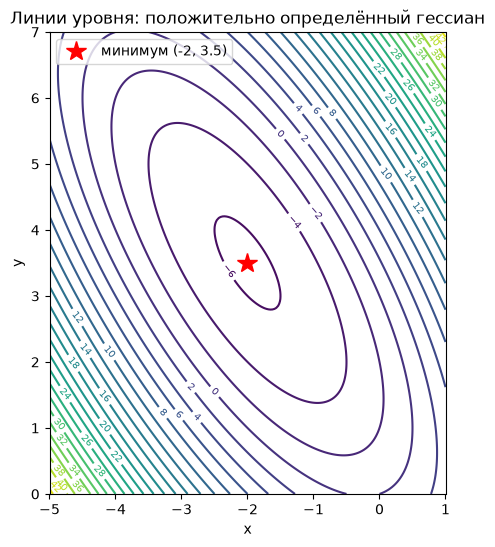

In [16]:
def minimum_function(point):
    x, y = point
    return 2*x**2 + y**2 + x - 3*y + 2*x*y

H_min = np.array([[4.0, 2.0], [2.0, 2.0]])
# система z_x = 0, z_y = 0:  4x + 2y = -1,  2x + 2y = 3
stationary_min = np.linalg.solve(H_min, np.array([-1.0, 3.0]))
eig_min = np.linalg.eigvalsh(H_min)

print("Стационарная точка:", stationary_min)
print("Численный градиент в ней:", central_gradient(minimum_function, stationary_min))
print("det H =", np.linalg.det(H_min), " собственные значения:", eig_min)
print("z(x*) =", minimum_function(stationary_min))

xs, ys = np.meshgrid(np.linspace(-5, 1, 200), np.linspace(0, 7, 200))
fig, ax = plt.subplots(figsize=(7, 6))
cs = ax.contour(xs, ys, minimum_function((xs, ys)), levels=25, cmap="viridis")
ax.clabel(cs, fontsize=7)
ax.plot(*stationary_min, "r*", ms=15, label="минимум (-2, 3.5)")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Линии уровня: положительно определённый гессиан")
ax.legend()
plt.show()

### Задание 6.2. Неопределённая кривизна и седло

Источник условия: практикум, с. 142, задача 3.

Исследуйте

$$
z=x^2-2y^2-4xy+3x.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, определитель и собственные значения.
- **[Markdown]** Покажите два направления, вдоль которых квадратичное изменение имеет разные знаки.
- **[Python]** Постройте линии уровня и трёхмерную поверхность около стационарной точки.
- **[Интерпретация]** Объясните, почему нулевой градиент ещё не гарантирует минимум.

#### Ваше решение

**Аналитическая часть.**

$z=x^2-2y^2-4xy+3x$.

$$
\begin{cases}
z_x=2x-4y+3=0,\\
z_y=-4y-4x=0\ \Rightarrow\ y=-x.
\end{cases}
\qquad\Rightarrow\qquad 2x+4x+3=0,\quad x=-0.5,\ y=0.5 .
$$

Стационарная точка $\mathbf x_*=(-0.5,\;0.5)$, $\;z(\mathbf x_*)=0.25-0.5+1-1.5=-0.75$.

$$
\mathbf H=\begin{pmatrix}2&-4\\-4&-4\end{pmatrix},\qquad \det\mathbf H=-8-16=-24<0 .
$$

Собственные значения: $\lambda^2+2\lambda-24=0$, откуда $\lambda_1=4$ с вектором $\tfrac1{\sqrt5}(2,-1)$ и $\lambda_2=-6$ с вектором $\tfrac1{\sqrt5}(1,2)$. Знаки разные, гессиан неопределённый, поэтому $\mathbf x_*$ — **седловая точка**.

**Два направления с разными знаками квадратичного изменения.** Градиент в $\mathbf x_*$ равен нулю, поэтому $\Delta z=\tfrac12\Delta^{\mathsf T}\mathbf H\Delta$ (точно, функция квадратичная):

* вдоль $\mathbf e_1=(1,0)$: $\;\Delta z=\tfrac12\cdot2\,s^2=+s^2>0$, функция растёт;
* вдоль $\mathbf e_2=(0,1)$: $\;\Delta z=\tfrac12\cdot(-4)\,s^2=-2s^2<0$, функция убывает;
* вдоль собственных векторов: $+2s^2$ и $-3s^2$ (то есть $\tfrac12\lambda_i s^2$).

**Численная проверка и интерпретация.**

Код подтверждает точку $(-0.5,\,0.5)$, собственные значения $-6$ и $4$, а также знаки приращений вдоль $\mathbf e_1$ и $\mathbf e_2$. Линии уровня — гиперболы, поверхность — «седло»: вдоль одного направления это парабола ветвями вверх, вдоль другого — ветвями вниз.

Нулевой градиент — только необходимое условие экстремума. Он значит лишь, что пропал линейный член. Дальше знак изменения функции определяет квадратичный член $\tfrac12\Delta^{\mathsf T}\mathbf H\Delta$, а он может быть разного знака в разных направлениях, как здесь. Поэтому тип точки определяют по гессиану, а не только по $\nabla z=0$.

Стационарная точка: [-0.5  0.5]  z = -0.75
Численный градиент в ней: [0. 0.]
det H = -23.999999999999993  собственные значения: [-6.  4.]
Собственные векторы (столбцы):
 [[ 0.447214 -0.894427]
 [ 0.894427  0.447214]]
s=0.1: вдоль e1 Δz=+0.0100 (=s^2), вдоль e2 Δz=-0.0200 (=-2s^2)
s=0.5: вдоль e1 Δz=+0.2500 (=s^2), вдоль e2 Δz=-0.5000 (=-2s^2)
s=1.0: вдоль e1 Δz=+1.0000 (=s^2), вдоль e2 Δz=-2.0000 (=-2s^2)


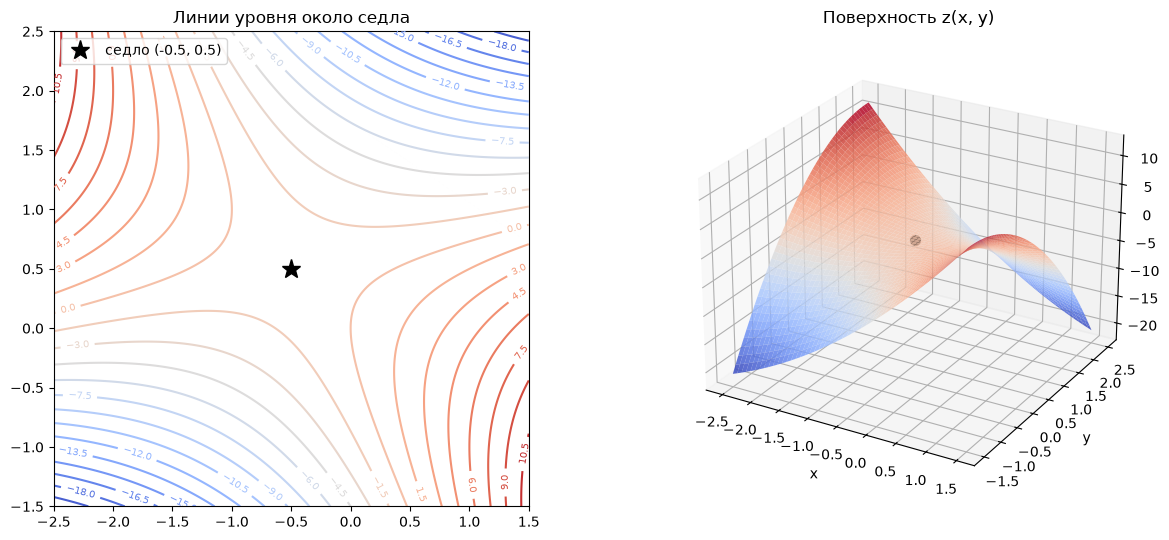

In [17]:
def saddle_function(point):
    x, y = point
    return x**2 - 2*y**2 - 4*x*y + 3*x

H_saddle = np.array([[2.0, -4.0], [-4.0, -4.0]])
# система z_x = 0, z_y = 0:  2x - 4y = -3,  -4x - 4y = 0
stationary_saddle = np.linalg.solve(H_saddle, np.array([-3.0, 0.0]))
eig_saddle, eigvec_saddle = np.linalg.eigh(H_saddle)

print("Стационарная точка:", stationary_saddle, " z =", saddle_function(stationary_saddle))
print("Численный градиент в ней:", central_gradient(saddle_function, stationary_saddle))
print("det H =", np.linalg.det(H_saddle), " собственные значения:", eig_saddle)
print("Собственные векторы (столбцы):\n", eigvec_saddle)
for s in [0.1, 0.5, 1.0]:
    up = saddle_function(stationary_saddle + s*np.array([1, 0])) - saddle_function(stationary_saddle)
    down = saddle_function(stationary_saddle + s*np.array([0, 1])) - saddle_function(stationary_saddle)
    print(f"s={s}: вдоль e1 Δz={up:+.4f} (=s^2), вдоль e2 Δz={down:+.4f} (=-2s^2)")

xs, ys = np.meshgrid(np.linspace(-2.5, 1.5, 200), np.linspace(-1.5, 2.5, 200))
zs = saddle_function((xs, ys))
fig = plt.figure(figsize=(13, 5.5))
ax1 = fig.add_subplot(1, 2, 1)
cs = ax1.contour(xs, ys, zs, levels=25, cmap="coolwarm")
ax1.clabel(cs, fontsize=7)
ax1.plot(*stationary_saddle, "k*", ms=14, label="седло (-0.5, 0.5)")
ax1.set_aspect("equal")
ax1.set_title("Линии уровня около седла")
ax1.legend(loc="upper left")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(xs, ys, zs, cmap="coolwarm", alpha=0.85, linewidth=0)
ax2.scatter(*stationary_saddle, saddle_function(stationary_saddle), color="k", s=50)
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_title("Поверхность z(x, y)")
ax2.view_init(elev=25, azim=-60)
plt.tight_layout()
plt.show()

### Задание 6.3. Квадратичная модель и HVP

Пусть

$$
\varphi(x,y)=e^{x+2y}+x^2,
\qquad \mathbf x_0=(0,0)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla\varphi(\mathbf x_0)$, $\mathbf H_\varphi(\mathbf x_0)$ и второе приближение

  $$
  \varphi(\mathbf x_0+\Delta)
  \approx \varphi(\mathbf x_0)
  +\nabla\varphi(\mathbf x_0)^{\mathsf T}\Delta
  +\frac12\Delta^{\mathsf T}\mathbf H_\varphi(\mathbf x_0)\Delta
  $$

  для $\Delta=(0.1,0.1)^{\mathsf T}$.
- **[Markdown]** Для $\mathbf v=(1,-1)^{\mathsf T}$ вычислите $\mathbf H\mathbf v$.
- **[Python]** Проверьте HVP центральной разностью градиента и сравните точное значение функции с линейным и квадратичным приближениями при уменьшающемся масштабе $\Delta$.
- **[Интерпретация]** Объясните, какую дополнительную информацию даёт квадратичный член по сравнению с одним градиентом.

#### Ваше решение

**Аналитическая часть.**

$\varphi(x,y)=e^{x+2y}+x^2$. Обозначим $E=e^{x+2y}$.

$$
\nabla\varphi=\begin{pmatrix}E+2x\\2E\end{pmatrix},\qquad
\mathbf H_\varphi=\begin{pmatrix}E+2&2E\\2E&4E\end{pmatrix}.
$$

В $\mathbf x_0=(0,0)$, где $E=1$: $\;\varphi(\mathbf x_0)=1$, $\;\nabla\varphi(\mathbf x_0)=(1,2)^{\mathsf T}$, $\;\mathbf H_\varphi(\mathbf x_0)=\begin{pmatrix}3&2\\2&4\end{pmatrix}$.

Для $\Delta=(0.1,0.1)^{\mathsf T}$: $\;\nabla\varphi^{\mathsf T}\Delta=0.1+0.2=0.3$, $\;\Delta^{\mathsf T}\mathbf H\Delta=0.01\,(3+2+2+4)=0.11$.

$$
\text{линейное: }1+0.3=1.3,\qquad
\text{квадратичное: }1+0.3+\tfrac12\cdot0.11=1.355,\qquad
\text{точное: }e^{0.3}+0.01\approx1.359859 .
$$

**HVP** для $\mathbf v=(1,-1)^{\mathsf T}$: $\;\mathbf H\mathbf v=\begin{pmatrix}3-2\\2-4\end{pmatrix}=\begin{pmatrix}1\\-2\end{pmatrix}$.

**Численная проверка и интерпретация.**

HVP через центральную разность градиента $\dfrac{\nabla\varphi(\mathbf x_0+\tfrac h2\mathbf v)-\nabla\varphi(\mathbf x_0-\tfrac h2\mathbf v)}{h}$ даёт $(1,-2)$. Гессиан при этом не строится, нужны только два вычисления градиента.

Ошибки приближений при уменьшении масштаба $\Delta=s\cdot(0.1,0.1)$ (таблица и график ниже):

| $s$ | ошибка линейного | ошибка квадратичного |
|---|---|---|
| 1 | $6.0\cdot10^{-2}$ | $4.9\cdot10^{-3}$ |
| 0.1 | $5.5\cdot10^{-4}$ | $4.5\cdot10^{-6}$ |
| 0.01 | $5.5\cdot10^{-6}$ | $4.5\cdot10^{-9}$ |

При уменьшении $\Delta$ в 10 раз ошибка линейной модели падает в $\approx100$ раз, то есть $O(\lVert\Delta\rVert^2)$, а квадратичной — в $\approx1000$ раз, то есть $O(\lVert\Delta\rVert^3)$.

Градиент даёт только наклон (касательную плоскость). Квадратичный член добавляет кривизну, то есть показывает, как меняется сам градиент при сдвиге. Поэтому квадратичная модель точнее и лучше описывает функцию при не очень маленьких $\Delta$. По гессиану также видно, в каких направлениях функция изгибается сильнее.

phi(x0) = 1.0  grad = [1. 2.] 
H =
 [[3. 2.]
 [2. 4.]]
H v (точно): [ 1. -2.]  H v (разность градиентов): [ 1. -2.]

    s |     точное |   линейное |     квадр. |  ош. лин. | ош. квадр.
 1.00 |   1.359859 |   1.300000 |   1.355000 |  5.99e-02 |   4.86e-03
 0.50 |   1.164334 |   1.150000 |   1.163750 |  1.43e-02 |   5.84e-04
 0.20 |   1.062237 |   1.060000 |   1.062200 |  2.24e-03 |   3.65e-05
 0.10 |   1.030555 |   1.030000 |   1.030550 |  5.55e-04 |   4.53e-06
 0.05 |   1.015138 |   1.015000 |   1.015137 |  1.38e-04 |   5.65e-07
 0.01 |   1.003006 |   1.003000 |   1.003005 |  5.50e-06 |   4.50e-09


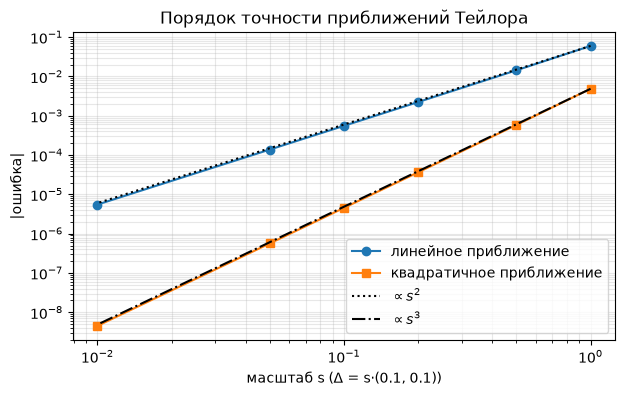

In [18]:
def phi(point):
    x, y = point
    return np.exp(x + 2*y) + x**2

def phi_gradient(point):
    x, y = point
    E = np.exp(x + 2*y)
    return np.array([E + 2*x, 2*E])

def phi_hessian(point):
    x, y = point
    E = np.exp(x + 2*y)
    return np.array([[E + 2, 2*E], [2*E, 4*E]])

x0_phi = np.zeros(2)
g0, H0 = phi_gradient(x0_phi), phi_hessian(x0_phi)
print("phi(x0) =", phi(x0_phi), " grad =", g0, "\nH =\n", H0)

v_hvp = np.array([1.0, -1.0])
h = 1e-5
hvp_numeric = (phi_gradient(x0_phi + h/2*v_hvp) - phi_gradient(x0_phi - h/2*v_hvp)) / h
print("H v (точно):", H0 @ v_hvp, " H v (разность градиентов):", hvp_numeric)

scales = np.array([1.0, 0.5, 0.2, 0.1, 0.05, 0.01])
lin_err, quad_err = [], []
print(f"\n{'s':>5} | {'точное':>10} | {'линейное':>10} | {'квадр.':>10} | {'ош. лин.':>9} | {'ош. квадр.':>10}")
for s in scales:
    d = s * np.array([0.1, 0.1])
    exact = phi(x0_phi + d)
    linear = phi(x0_phi) + g0 @ d
    quadratic = linear + 0.5 * d @ H0 @ d
    lin_err.append(abs(exact - linear))
    quad_err.append(abs(exact - quadratic))
    print(f"{s:5.2f} | {exact:10.6f} | {linear:10.6f} | {quadratic:10.6f} | {lin_err[-1]:9.2e} | {quad_err[-1]:10.2e}")

plt.figure(figsize=(7, 4))
plt.loglog(scales, lin_err, "o-", label="линейное приближение")
plt.loglog(scales, quad_err, "s-", label="квадратичное приближение")
plt.loglog(scales, lin_err[0] * scales**2, "k:", label="$\\propto s^2$")
plt.loglog(scales, quad_err[0] * scales**3, "k-.", label="$\\propto s^3$")
plt.xlabel("масштаб s (Δ = s·(0.1, 0.1))")
plt.ylabel("|ошибка|")
plt.title("Порядок точности приближений Тейлора")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## 7. Матричное дифференцирование

### Короткая теория

Для векторного аргумента полезны тождества

$$
\frac{\partial(\mathbf a^{\mathsf T}\mathbf x)}{\partial\mathbf x}=\mathbf a,
\qquad
\frac{\partial(\mathbf x^{\mathsf T}\mathbf A\mathbf x)}{\partial\mathbf x}
=(\mathbf A+\mathbf A^{\mathsf T})\mathbf x.
$$

Для матричного аргумента производная скалярной функции имеет ту же форму, что и матрица:

$$
\left(\frac{\partial f}{\partial\mathbf X}\right)_{ij}
=\frac{\partial f}{\partial X_{ij}}.
$$

В частности,

$$
\frac{\partial}{\partial\mathbf X}
(\mathbf a^{\mathsf T}\mathbf X\mathbf b)
=\mathbf a\mathbf b^{\mathsf T},
\qquad
\frac{\partial}{\partial\mathbf X}
\operatorname{tr}(\mathbf X^{\mathsf T}\mathbf A)=\mathbf A.
$$

См. векторные градиенты, с. 42 и матричные и следовые тождества, с. 42–43.

### Задание 7.1. Линейно-квадратичная форма

Для

$$
f(\mathbf x)=\mathbf a^{\mathsf T}\mathbf x+\mathbf x^{\mathsf T}\mathbf A\mathbf x,
$$

$$
\mathbf A=\begin{pmatrix}2&-1\\3&1\end{pmatrix},
\quad
\mathbf a=\begin{pmatrix}1\\-2\end{pmatrix},
\quad
\mathbf x=\begin{pmatrix}2\\-1\end{pmatrix},
$$

найдите значение, градиент и гессиан.

- **[Бумага]** Сначала раскройте выражение покоординатно, затем примените матричное тождество.
- **[Markdown]** Объясните появление симметричной части $\mathbf A+\mathbf A^{\mathsf T}$.
- **[Python]** Проверьте градиент и гессиан конечными разностями.
- **[Интерпретация]** Покажите, что кососимметричная часть $\mathbf A$ не влияет на $\mathbf x^{\mathsf T}\mathbf A\mathbf x$.

#### Ваше решение

**Аналитическая часть.**

**Покоординатно.** $\mathbf x^{\mathsf T}\mathbf A\mathbf x=\sum_{i,j}A_{ij}x_ix_j=2x_1^2+(-1+3)x_1x_2+x_2^2=2x_1^2+2x_1x_2+x_2^2$, поэтому

$$
f(\mathbf x)=x_1-2x_2+2x_1^2+2x_1x_2+x_2^2 .
$$

$$
\frac{\partial f}{\partial x_1}=1+4x_1+2x_2,\qquad
\frac{\partial f}{\partial x_2}=-2+2x_1+2x_2,\qquad
\nabla^2f=\begin{pmatrix}4&2\\2&2\end{pmatrix}.
$$

В точке $\mathbf x=(2,-1)$: $\;f=2+2+8-4+1=9$, $\;\nabla f=(1+8-2,\;-2+4-2)=(7,\;0)$.

**Через тождество.** $\;\nabla f=\mathbf a+(\mathbf A+\mathbf A^{\mathsf T})\mathbf x$, $\;\nabla^2f=\mathbf A+\mathbf A^{\mathsf T}$:

$$
\mathbf A+\mathbf A^{\mathsf T}=\begin{pmatrix}4&2\\2&2\end{pmatrix},\quad
(\mathbf A+\mathbf A^{\mathsf T})\mathbf x=\begin{pmatrix}6\\2\end{pmatrix},\quad
\nabla f=\begin{pmatrix}1\\-2\end{pmatrix}+\begin{pmatrix}6\\2\end{pmatrix}=\begin{pmatrix}7\\0\end{pmatrix}.
$$

Значение: $\mathbf a^{\mathsf T}\mathbf x=2+2=4$, $\;\mathbf A\mathbf x=(5,5)^{\mathsf T}$, $\;\mathbf x^{\mathsf T}\mathbf A\mathbf x=10-5=5$, $\;f=9$. Совпадает.

**Откуда $\mathbf A+\mathbf A^{\mathsf T}$.** Вектор $\mathbf x$ входит в форму дважды, слева и справа:

$$
\frac{\partial}{\partial x_m}\sum_{i,j}A_{ij}x_ix_j=\sum_jA_{mj}x_j+\sum_iA_{im}x_i=(\mathbf A\mathbf x)_m+(\mathbf A^{\mathsf T}\mathbf x)_m .
$$

Каждое вхождение даёт своё слагаемое. Формула $2\mathbf A\mathbf x$ верна только для симметричной $\mathbf A$.

**Численная проверка и интерпретация.**

Численные градиент $(7,0)$ и гессиан $\begin{pmatrix}4&2\\2&2\end{pmatrix}$ совпадают с аналитическими (вывод ниже). Градиент в этой точке направлен строго по оси $x_1$: по $x_2$ функция стационарна.

**Кососимметричная часть не влияет.** Запишем $\mathbf A=\mathbf S+\mathbf K$, где $\mathbf S=\tfrac12(\mathbf A+\mathbf A^{\mathsf T})=\begin{pmatrix}2&1\\1&1\end{pmatrix}$ и $\mathbf K=\tfrac12(\mathbf A-\mathbf A^{\mathsf T})=\begin{pmatrix}0&-2\\2&0\end{pmatrix}$. Число $\mathbf x^{\mathsf T}\mathbf K\mathbf x$ равно своему транспонированию:
$\mathbf x^{\mathsf T}\mathbf K\mathbf x=(\mathbf x^{\mathsf T}\mathbf K\mathbf x)^{\mathsf T}=\mathbf x^{\mathsf T}\mathbf K^{\mathsf T}\mathbf x=-\mathbf x^{\mathsf T}\mathbf K\mathbf x$, поэтому оно равно нулю. Значит, $\mathbf x^{\mathsf T}\mathbf A\mathbf x=\mathbf x^{\mathsf T}\mathbf S\mathbf x=8-4+1=5$. В коде $\mathbf x^{\mathsf T}\mathbf K\mathbf x=0$ и для нашей точки, и для нескольких других. Квадратичная форма зависит только от симметричной части $\mathbf A$, поэтому в градиенте и стоит $\mathbf A+\mathbf A^{\mathsf T}=2\mathbf S$.

In [19]:
A_quad = np.array([[2, -1], [3, 1]], dtype=float)
a_quad = np.array([1.0, -2.0])
x_quad = np.array([2.0, -1.0])

def lq_form(x):
    return a_quad @ x + x @ A_quad @ x

value_quad = lq_form(x_quad)
grad_quad = a_quad + (A_quad + A_quad.T) @ x_quad
hess_quad = A_quad + A_quad.T

h = 1e-4
grad_quad_numeric = central_gradient(lq_form, x_quad, h)
hess_quad_numeric = np.zeros((2, 2))
for j in range(2):  # j-й столбец гессиана = разность градиентов вдоль e_j
    e_j = np.zeros(2)
    e_j[j] = 1.0
    hess_quad_numeric[:, j] = (central_gradient(lq_form, x_quad + h/2*e_j, h)
                               - central_gradient(lq_form, x_quad - h/2*e_j, h)) / h

print("f(x) =", value_quad)
print("∇f (аналит.):", grad_quad, " (числ.):", grad_quad_numeric)
print("Гессиан (аналит.):\n", hess_quad, "\nГессиан (числ.):\n", hess_quad_numeric)

A_sym = 0.5 * (A_quad + A_quad.T)
A_skew = 0.5 * (A_quad - A_quad.T)
print("\nS =\n", A_sym, "\nK =\n", A_skew)
print("x^T A x =", x_quad @ A_quad @ x_quad, " x^T S x =", x_quad @ A_sym @ x_quad,
      " x^T K x =", x_quad @ A_skew @ x_quad)
for x_test in [np.array([1.0, 0.0]), np.array([1.0, 1.0]), np.array([-3.0, 2.0])]:
    print("x =", x_test, " x^T K x =", x_test @ A_skew @ x_test)

f(x) = 9.0
∇f (аналит.): [7. 0.]  (числ.): [7. 0.]
Гессиан (аналит.):
 [[4. 2.]
 [2. 2.]] 
Гессиан (числ.):
 [[4. 2.]
 [2. 2.]]

S =
 [[2. 1.]
 [1. 1.]] 
K =
 [[ 0. -2.]
 [ 2.  0.]]
x^T A x = 5.0  x^T S x = 5.0  x^T K x = 0.0
x = [1. 0.]  x^T K x = 0.0
x = [1. 1.]  x^T K x = 0.0
x = [-3.  2.]  x^T K x = 0.0


### Задание 7.2. Производная по матрице

Пусть

$$
s(\mathbf M)=\mathbf a^{\mathsf T}\mathbf M\mathbf b,
\quad
\mathbf a=(1,-2)^{\mathsf T},
\quad
\mathbf b=(3,1,-1)^{\mathsf T},
$$

$$
\mathbf M=
\begin{pmatrix}1&2&0\\-1&3&4\end{pmatrix}.
$$

- **[Бумага]** Раскройте $s=\sum_i\sum_j a_iM_{ij}b_j$ и найдите каждую $\partial s/\partial M_{ij}$.
- **[Markdown]** Сверните результат в $\mathbf a\mathbf b^{\mathsf T}$ и перепишите скаляр через след.
- **[Python]** Изменяйте каждый элемент $M_{ij}$ отдельно и сравните численный градиент с внешним произведением.
- **[Интерпретация]** Объясните, почему форма градиента совпадает с формой матрицы параметров.

#### Ваше решение

**Аналитическая часть.**

$$
s(\mathbf M)=\mathbf a^{\mathsf T}\mathbf M\mathbf b=\sum_{i=1}^{2}\sum_{j=1}^{3}a_iM_{ij}b_j .
$$

Каждый элемент $M_{ij}$ входит в сумму ровно один раз, с коэффициентом $a_ib_j$, поэтому

$$
\frac{\partial s}{\partial M_{ij}}=a_ib_j
\quad\Longrightarrow\quad
\frac{\partial s}{\partial\mathbf M}=\mathbf a\mathbf b^{\mathsf T}
=\begin{pmatrix}1\\-2\end{pmatrix}(3,\;1,\;-1)
=\begin{pmatrix}3&1&-1\\-6&-2&2\end{pmatrix}.
$$

Значение: $\mathbf M\mathbf b=(3+2+0,\;-3+3-4)^{\mathsf T}=(5,\,-4)^{\mathsf T}$, $\;s=1\cdot5+(-2)(-4)=13$.

**Через след.** Скаляр равен своему следу, а след инвариантен к циклической перестановке:

$$
s=\operatorname{tr}(\mathbf a^{\mathsf T}\mathbf M\mathbf b)=\operatorname{tr}(\mathbf M\mathbf b\mathbf a^{\mathsf T})
=\operatorname{tr}\!\big(\mathbf M^{\mathsf T}(\mathbf a\mathbf b^{\mathsf T})\big)=\sum_{i,j}M_{ij}(\mathbf a\mathbf b^{\mathsf T})_{ij}.
$$

По тождеству $\frac{\partial}{\partial\mathbf X}\operatorname{tr}(\mathbf X^{\mathsf T}\mathbf A)=\mathbf A$ с $\mathbf A=\mathbf a\mathbf b^{\mathsf T}$ сразу получаем $\nabla_{\mathbf M}s=\mathbf a\mathbf b^{\mathsf T}$.

**Численная проверка и интерпретация.**

Поочерёдное возмущение каждого из 6 элементов $M_{ij}$ (это делает `central_gradient`, перебирая `.flat`) даёт матрицу, совпадающую с `np.outer(a, b)` до ошибки округления. Функция линейна по $\mathbf M$, поэтому центральная разность точна. Значения через `@` и через след равны $13$.

Градиент по матрице — это все частные производные $\partial s/\partial M_{ij}$, записанные на тех же местах, где стоят элементы $M_{ij}$. Поэтому его форма $2\times3$, как у $\mathbf M$. Так удобно: элемент $(i,j)$ градиента сразу показывает, как $s$ зависит от $M_{ij}$, и шаг $\mathbf M-\eta\nabla_{\mathbf M}s$ можно делать поэлементно.

In [20]:
a_matrix = np.array([1.0, -2.0])
b_matrix = np.array([3.0, 1.0, -1.0])
M_parameter = np.array([[1, 2, 0], [-1, 3, 4]], dtype=float)

def bilinear(M):
    return a_matrix @ M @ b_matrix

s_value = bilinear(M_parameter)
s_trace = np.trace(M_parameter.T @ np.outer(a_matrix, b_matrix))
grad_M_exact = np.outer(a_matrix, b_matrix)
grad_M_numeric = central_gradient(bilinear, M_parameter)

print("s = a^T M b =", s_value, " через след:", s_trace)
print("∂s/∂M = a b^T:\n", grad_M_exact)
print("Численный градиент (по каждому M_ij):\n", grad_M_numeric)
print("Форма градиента:", grad_M_numeric.shape, "= форма M:", M_parameter.shape)
print("Макс. ошибка:", np.max(np.abs(grad_M_exact - grad_M_numeric)))

s = a^T M b = 13.0  через след: 13.0
∂s/∂M = a b^T:
 [[ 3.  1. -1.]
 [-6. -2.  2.]]
Численный градиент (по каждому M_ij):
 [[ 3.  1. -1.]
 [-6. -2.  2.]]
Форма градиента: (2, 3) = форма M: (2, 3)
Макс. ошибка: 1.2812417793384157e-10


### Задание 7.3. Сумма потерь, след и матричный градиент

Для общего пакета данных определим

$$
Q(\mathbf W)=\frac{1}{2N}\lVert\mathbf X\mathbf W-\mathbf Y\rVert_F^2.
$$

- **[Бумага]** Запишите $Q$ тремя способами:

  $$
  Q=\frac{1}{2N}\sum_{n=1}^N\sum_{k=1}^K
  \left(\sum_{d=1}^D X_{nd}W_{dk}-Y_{nk}\right)^2,
  $$

  через норму Фробениуса и через след.
- **[Markdown]** Выведите по индексам

  $$
  \nabla_{\mathbf W}Q
  =\frac1N\mathbf X^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)
  $$

  и действие гессиана на матрицу-направление $\Delta\mathbf W$.
- **[Python]** Вычислите $Q(\mathbf W_0)$, градиент и проверьте каждый элемент конечными разностями.
- **[Интерпретация]** Сопоставьте индексы $d,k$ у градиента индексам параметра $W_{dk}$.

#### Ваше решение

**Аналитическая часть.**

$\mathbf X\in\mathbb R^{4\times3}$, $\mathbf W\in\mathbb R^{3\times2}$, $\mathbf Y\in\mathbb R^{4\times2}$, остаток $\mathbf R=\mathbf X\mathbf W-\mathbf Y\in\mathbb R^{4\times2}$, $R_{nk}=\sum_dX_{nd}W_{dk}-Y_{nk}$.

Три эквивалентные записи:

$$
Q=\frac{1}{2N}\sum_{n=1}^N\sum_{k=1}^K\Big(\sum_{d=1}^DX_{nd}W_{dk}-Y_{nk}\Big)^2
=\frac{1}{2N}\lVert\mathbf X\mathbf W-\mathbf Y\rVert_F^2
=\frac{1}{2N}\operatorname{tr}\!\big((\mathbf X\mathbf W-\mathbf Y)^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)\big).
$$

**Градиент по индексам.** $\;\dfrac{\partial R_{nk}}{\partial W_{pq}}=X_{np}\,\delta_{kq}$, поэтому

$$
\frac{\partial Q}{\partial W_{pq}}
=\frac{1}{2N}\sum_{n,k}2R_{nk}\,X_{np}\,\delta_{kq}
=\frac1N\sum_nX_{np}R_{nq}
=\frac1N(\mathbf X^{\mathsf T}\mathbf R)_{pq}
\quad\Longrightarrow\quad
\nabla_{\mathbf W}Q=\frac1N\mathbf X^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y).
$$

Размеры: $(3\times4)(4\times2)=3\times2$, как у $\mathbf W$.

**Действие гессиана на направление $\Delta\mathbf W$.** $\;\nabla Q(\mathbf W+\varepsilon\Delta\mathbf W)=\frac1N\mathbf X^{\mathsf T}(\mathbf R+\varepsilon\mathbf X\Delta\mathbf W)$, поэтому

$$
\mathcal H[\Delta\mathbf W]=\frac{d}{d\varepsilon}\nabla Q(\mathbf W+\varepsilon\Delta\mathbf W)\Big|_{\varepsilon=0}=\frac1N\mathbf X^{\mathsf T}\mathbf X\,\Delta\mathbf W,
\qquad
\langle\Delta\mathbf W,\mathcal H[\Delta\mathbf W]\rangle_F=\frac1N\lVert\mathbf X\Delta\mathbf W\rVert_F^2\ge0 .
$$

Гессиан не зависит от $\mathbf W$, потому что $Q$ квадратичная, и $\langle\Delta\mathbf W,\mathcal H[\Delta\mathbf W]\rangle\ge0$, то есть $Q$ выпуклая.

**Подстановка $\mathbf W_0$.**

$$
\mathbf X\mathbf W_0=\begin{pmatrix}0.7&-0.5\\-0.1&0.3\\0.6&-0.2\\0.1&0.7\end{pmatrix},\quad
\mathbf R=\begin{pmatrix}0.5&-1.3\\-0.8&0.2\\0&-0.6\\0&-0.2\end{pmatrix},\quad
\lVert\mathbf R\rVert_F^2=3.02,\quad Q(\mathbf W_0)=\frac{3.02}{8}=0.3775 .
$$

$$
\nabla_{\mathbf W}Q(\mathbf W_0)=\frac14\mathbf X^{\mathsf T}\mathbf R=\frac14\begin{pmatrix}0.5&-1.7\\-0.8&-0.8\\-1.3&1.3\end{pmatrix}=\begin{pmatrix}0.125&-0.425\\-0.2&-0.2\\-0.325&0.325\end{pmatrix}.
$$

**Численная проверка и интерпретация.**

Три формы $Q$ (индексная сумма, норма Фробениуса, след) дают $0.3775$. Поэлементная проверка всех 6 элементов градиента и действие гессиана (через разность градиентов вдоль $\Delta\mathbf W$) совпадают с формулами с ошибкой $\sim10^{-10}$ (вывод ниже).

Элемент $(\nabla_{\mathbf W}Q)_{dk}$ показывает, как $Q$ зависит от веса $W_{dk}$, то есть от того, с каким весом $d$-я входная координата идёт в $k$-й выход. Индексы $d,k$ у градиента те же, что у параметра: строка — входная координата, столбец — выход. Индекс наблюдения $n$ в $\mathbf X^{\mathsf T}\mathbf R$ внутренний, по нему суммируем. Например, $(\nabla Q)_{12}=-0.425<0$, значит если немного увеличить $W_{12}$, $Q$ уменьшится.

In [21]:
def matrix_least_squares(W):
    residual = X_data @ W - Y_data
    return 0.5 * np.sum(residual**2) / len(X_data)

N_obs = len(X_data)

def least_squares_gradient(W):
    return X_data.T @ (X_data @ W - Y_data) / N_obs

def least_squares_hessian_action(dW):
    return X_data.T @ (X_data @ dW) / N_obs

R0 = X_data @ W_initial - Y_data
Q_index = 0.0
for n in range(N_obs):
    for k in range(Y_data.shape[1]):
        Q_index += (sum(X_data[n, d] * W_initial[d, k] for d in range(X_data.shape[1])) - Y_data[n, k])**2
Q_index /= 2 * N_obs
Q_frobenius = 0.5 * np.linalg.norm(R0, ord="fro")**2 / N_obs
Q_trace = 0.5 * np.trace(R0.T @ R0) / N_obs
print("XW0 =\n", X_data @ W_initial, "\nR =\n", R0)
print(f"Q (индексы) = {Q_index:.6f}, Q (Фробениус) = {Q_frobenius:.6f}, Q (след) = {Q_trace:.6f}")

grad_Q_exact = least_squares_gradient(W_initial)
grad_Q_numeric = central_gradient(matrix_least_squares, W_initial, h=1e-6)
print("\n∇Q аналитически:\n", grad_Q_exact)
print("∇Q численно (каждый W_dk):\n", grad_Q_numeric)
print("Форма:", grad_Q_exact.shape, " макс. ошибка:", np.max(np.abs(grad_Q_exact - grad_Q_numeric)))

dW = np.array([[1.0, 0.0], [0.0, -1.0], [0.5, 0.5]])
h = 1e-5
hvp_Q_numeric = (least_squares_gradient(W_initial + h/2*dW) - least_squares_gradient(W_initial - h/2*dW)) / h
print("\nH[ΔW] = X^T X ΔW / N:\n", least_squares_hessian_action(dW))
print("Разность градиентов:\n", hvp_Q_numeric)
print("<ΔW, H[ΔW]> =", np.sum(dW * least_squares_hessian_action(dW)),
      " = ||X ΔW||^2 / N =", np.linalg.norm(X_data @ dW)**2 / N_obs)

XW0 =
 [[ 0.7 -0.5]
 [-0.1  0.3]
 [ 0.6 -0.2]
 [ 0.1  0.7]] 
R =
 [[ 0.5 -1.3]
 [-0.8  0.2]
 [ 0.  -0.6]
 [ 0.  -0.2]]
Q (индексы) = 0.377500, Q (Фробениус) = 0.377500, Q (след) = 0.377500

∇Q аналитически:
 [[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
∇Q численно (каждый W_dk):
 [[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
Форма: (3, 2)  макс. ошибка: 1.4331003050926938e-10

H[ΔW] = X^T X ΔW / N:
 [[ 0.5    0.   ]
 [ 0.125 -1.125]
 [-0.125 -0.375]]
Разность градиентов:
 [[ 0.5    0.   ]
 [ 0.125 -1.125]
 [-0.125 -0.375]]
<ΔW, H[ΔW]> = 1.375  = ||X ΔW||^2 / N = 1.375


## 8. Сквозная составная функция

### Короткая теория

Для сигмоиды

$$
\sigma(z)=\frac{1}{1+e^{-z}},
\qquad
\sigma'(z)=\sigma(z)(1-\sigma(z)).
$$

В матричном выражении нелинейная функция применяется поэлементно. Чтобы не смешивать матричное и поэлементное умножение, будем обозначать последнее символом $\odot$.

Цепное правило для композиции применяется от скалярного результата к каждому промежуточному аргументу. Это та же идея, что произведение якобианов и VJP на с. 41, но записанная сразу в формах нужных массивов.

### Задание 8.1. Прямое вычисление и размерности

- **[Бумага]** Для элемента $Z_{nk}$ запишите

  $$
  Z_{nk}=\sum_{d=1}^{D}X_{nd}W_{dk}+b_k.
  $$

  Затем запишите $H_{nk}$ и $\mathcal L$ как суммы по индексам.
- **[Markdown]** Составьте таблицу объектов $\mathbf X,\mathbf W,\mathbf b,\mathbf Z,\mathbf H,\mathbf Y,\mathcal L$ с размерностями и типами.
- **[Python]** Выполните прямое вычисление с начальными параметрами. Для устойчивости ограничьте аргумент `exp` диапазоном `[-50, 50]`.
- **[Интерпретация]** Объясните, почему добавление $\mathbf b$ к каждой строке является расширением по строкам, а не матричным произведением двух исходных массивов.

#### Ваше решение

**Аналитическая часть.**

$$
Z_{nk}=\sum_{d=1}^{D}X_{nd}W_{dk}+b_k,\qquad
H_{nk}=\sigma(Z_{nk})=\frac{1}{1+e^{-Z_{nk}}},
$$

$$
\mathcal L=\frac{1}{2N}\sum_{n=1}^{N}\sum_{k=1}^{K}(H_{nk}-Y_{nk})^2+\frac\lambda2\sum_{d=1}^{D}\sum_{k=1}^{K}W_{dk}^2 .
$$

| Объект | Тип | Размерность | Индексы | Роль |
|---|---|---|---|---|
| $\mathbf X$ | матрица | $4\times3$ ($N\times D$) | $n,d$ | данные, строка — наблюдение |
| $\mathbf W$ | матрица | $3\times2$ ($D\times K$) | $d,k$ | параметр |
| $\mathbf b$ | вектор | $2$ ($K$) | $k$ | параметр (смещение) |
| $\mathbf Z$ | матрица | $4\times2$ ($N\times K$) | $n,k$ | линейный выход |
| $\mathbf H$ | матрица | $4\times2$ ($N\times K$) | $n,k$ | выход после сигмоиды, $H_{nk}\in(0,1)$ |
| $\mathbf Y$ | матрица | $4\times2$ ($N\times K$) | $n,k$ | целевые значения |
| $\mathcal L$ | скаляр | $1$ | — | целевая функция |

**Проверка одного элемента:** $\;Z_{11}=X_{11}W_{11}+X_{12}W_{21}+X_{13}W_{31}+b_1=1\cdot0.2+0\cdot0.4+(-1)(-0.5)+0.1=0.8$.

**Численная проверка и интерпретация.**

$$
\mathbf Z=\begin{pmatrix}0.8&-0.7\\0&0.1\\0.7&-0.4\\0.2&0.5\end{pmatrix},\qquad
\mathbf H\approx\begin{pmatrix}0.6900&0.3318\\0.5000&0.5250\\0.6682&0.4013\\0.5498&0.6225\end{pmatrix}.
$$

Слагаемое данных $\frac1{2N}\lVert\mathbf H-\mathbf Y\rVert_F^2\approx0.120489$. Регуляризация $\frac\lambda2\lVert\mathbf W_0\rVert_F^2=0.025\cdot0.59=0.01475$. Итого $\mathcal L(\mathbf W_0,\mathbf b_0)\approx0.135239$. Ручное $Z_{11}=0.8$ совпадает с кодом.

**Про $\mathbf b$.** $\mathbf X$ ($4\times3$) и $\mathbf b$ (2 элемента) по размерам перемножить нельзя, да это и не нужно: одно и то же смещение $\mathbf b$ просто прибавляется к каждой строке (к каждому наблюдению). Запись $\mathbf1_N\mathbf b^{\mathsf T}$ — это матрица $4\times2$, у которой все строки равны $\mathbf b^{\mathsf T}$. В NumPy `X @ W + b` делает это сам (broadcasting), и в коде я проверил, что ответ совпадает с явной записью через `ones`.

In [22]:
N_obs, D_in = X_data.shape
K_out = Y_data.shape[1]

Z_forward = X_data @ W_initial + b_initial                  # broadcasting: + 1_N b^T
Z_explicit = X_data @ W_initial + np.ones((N_obs, 1)) @ b_initial[None, :]
H_forward = sigmoid(Z_forward)
data_term = 0.5 * np.sum((H_forward - Y_data)**2) / N_obs
reg_term = 0.5 * regularization * np.sum(W_initial**2)
loss_forward = data_term + reg_term

for name, obj in [("X", X_data), ("W", W_initial), ("b", b_initial), ("Z", Z_forward),
                  ("H", H_forward), ("Y", Y_data), ("L", np.array(loss_forward))]:
    print(f"{name}: форма {obj.shape}")
print("\nZ =\n", Z_forward)
print("Broadcasting совпадает с 1_N b^T:", np.allclose(Z_forward, Z_explicit))
Z11_manual = sum(X_data[0, d] * W_initial[d, 0] for d in range(D_in)) + b_initial[0]
print(f"Z_11 вручную = {Z11_manual:.4f}, из матрицы = {Z_forward[0, 0]:.4f}")
print("\nH = sigma(Z) =\n", H_forward)
print(f"\nСлагаемое данных = {data_term:.6f}")
print(f"Регуляризация    = {reg_term:.6f}  (||W||_F^2 = {np.sum(W_initial**2):.2f})")
print(f"L(W0, b0)        = {loss_forward:.6f}")

X: форма (4, 3)
W: форма (3, 2)
b: форма (2,)
Z: форма (4, 2)
H: форма (4, 2)
Y: форма (4, 2)
L: форма ()

Z =
 [[ 0.8 -0.7]
 [ 0.   0.1]
 [ 0.7 -0.4]
 [ 0.2  0.5]]
Broadcasting совпадает с 1_N b^T: True
Z_11 вручную = 0.8000, из матрицы = 0.8000

H = sigma(Z) =
 [[0.689974 0.331812]
 [0.5      0.524979]
 [0.668188 0.401312]
 [0.549834 0.622459]]

Слагаемое данных = 0.120489
Регуляризация    = 0.014750  (||W||_F^2 = 0.59)
L(W0, b0)        = 0.135239


### Задание 8.2. Распространение производных по композиции

Обозначьте $\mathbf R=\mathbf H-\mathbf Y$.

- **[Бумага]** Последовательно получите

  $$
  \mathbf G_H=\frac{1}{N}\mathbf R,
  \qquad
  \mathbf G_Z=\mathbf G_H\odot\mathbf H\odot(1-\mathbf H),
  $$

  $$
  \nabla_{\mathbf W}\mathcal L
  =\mathbf X^{\mathsf T}\mathbf G_Z+\lambda\mathbf W,
  \qquad
  \nabla_{\mathbf b}\mathcal L
  =\mathbf G_Z^{\mathsf T}\mathbf1_N.
  $$
- **[Markdown]** После каждой строки подпишите размерность. Отдельно объясните происхождение $\lambda\mathbf W$.
- **[Python]** Реализуйте одну функцию, возвращающую $\mathcal L$, $\nabla_{\mathbf W}\mathcal L$ и $\nabla_{\mathbf b}\mathcal L$.
- **[Интерпретация]** Опишите вычисление производных как движение по композиции в порядке, обратном прямому вычислению значений.

#### Ваше решение

**Аналитическая часть.**

Идём от скаляра $\mathcal L$ назад по композиции $\;(\mathbf W,\mathbf b)\to\mathbf Z\to\mathbf H\to\mathcal L$, $\;\mathbf R=\mathbf H-\mathbf Y$.

1. **По $\mathbf H$.** $\mathcal L$ зависит от $H_{nk}$ только через $\frac1{2N}(H_{nk}-Y_{nk})^2$:
   $$\mathbf G_H=\frac{\partial\mathcal L}{\partial\mathbf H}=\frac1N\mathbf R\qquad[4\times2].$$
2. **По $\mathbf Z$.** $H_{nk}=\sigma(Z_{nk})$ зависит только от своего $Z_{nk}$, поэтому якобиан поэлементной функции диагонален, и VJP сводится к поэлементному умножению на $\sigma'(Z_{nk})=H_{nk}(1-H_{nk})$:
   $$\mathbf G_Z=\mathbf G_H\odot\mathbf H\odot(\mathbf 1-\mathbf H)\qquad[4\times2].$$
3. **По $\mathbf W$.** $\dfrac{\partial Z_{nk}}{\partial W_{pq}}=X_{np}\delta_{kq}$, поэтому $\dfrac{\partial}{\partial W_{pq}}(\text{данные})=\sum_nX_{np}(G_Z)_{nq}=(\mathbf X^{\mathsf T}\mathbf G_Z)_{pq}$. Регуляризация даёт $\dfrac{\partial}{\partial W_{pq}}\dfrac\lambda2\sum_{d,k}W_{dk}^2=\lambda W_{pq}$:
   $$\nabla_{\mathbf W}\mathcal L=\mathbf X^{\mathsf T}\mathbf G_Z+\lambda\mathbf W\qquad[(3\times4)(4\times2)=3\times2].$$
4. **По $\mathbf b$.** $\dfrac{\partial Z_{nk}}{\partial b_q}=\delta_{kq}$ для *каждого* $n$: смещение скопировано во все строки, поэтому вклады строк суммируются:
   $$\nabla_{\mathbf b}\mathcal L=\mathbf G_Z^{\mathsf T}\mathbf 1_N=\sum_n(\mathbf G_Z)_{n\,\cdot}\qquad[(2\times4)(4\times1)=2].$$

**Откуда $\lambda\mathbf W$.** Это производная регуляризации $\frac\lambda2\lVert\mathbf W\rVert_F^2=\frac\lambda2\sum W_{dk}^2$: производная $W_{dk}^2$ равна $2W_{dk}$, двойка сокращается с $\frac12$. $\mathbf b$ в регуляризацию не входит, поэтому в $\nabla_{\mathbf b}\mathcal L$ такого слагаемого нет.

**Численная проверка и интерпретация.**

В начальной точке (вывод ниже):

$$
\nabla_{\mathbf W}\mathcal L\approx\begin{pmatrix}0.012147&-0.024566\\0.066950&-0.001038\\-0.035867&0.046140\end{pmatrix},\qquad
\nabla_{\mathbf b}\mathcal L\approx\begin{pmatrix}0.045317\\-0.015683\end{pmatrix}.
$$

Формы $3\times2$ и $2$ совпадают с формами параметров.

Значения считаем в порядке $\mathbf X,\mathbf W,\mathbf b\to\mathbf Z\to\mathbf H\to\mathcal L$, а производные — в обратном: $\mathcal L\to\mathbf G_H\to\mathbf G_Z\to(\nabla_{\mathbf W},\nabla_{\mathbf b})$. На каждом шаге уже полученный градиент умножается на производную очередного блока (как VJP в задании 5.3). При этом используется $\mathbf H$, посчитанная при прямом вычислении.

In [23]:
def objective_and_grad(W, b):
    N = X_data.shape[0]
    Z = X_data @ W + b                      # (N, K)
    H = sigmoid(Z)                          # (N, K)
    R = H - Y_data                          # (N, K)
    loss = 0.5 * np.sum(R**2) / N + 0.5 * regularization * np.sum(W**2)

    G_H = R / N                             # (N, K)
    G_Z = G_H * H * (1.0 - H)               # (N, K), поэлементно
    grad_W = X_data.T @ G_Z + regularization * W   # (D, K)
    grad_b = G_Z.T @ np.ones(N)             # (K,)
    return loss, grad_W, grad_b

loss_0, grad_W_0, grad_b_0 = objective_and_grad(W_initial, b_initial)
print(f"L(W0, b0) = {loss_0:.6f}")
print("∇_W L, форма", grad_W_0.shape, ":\n", grad_W_0)
print("∇_b L, форма", grad_b_0.shape, ":", grad_b_0)

L(W0, b0) = 0.135239
∇_W L, форма (3, 2) :
 [[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
∇_b L, форма (2,) : [ 0.045317 -0.015683]


### Задание 8.3. Проверка каждого параметра

- **[Бумага]** Запишите центральную разность для одного элемента $W_{dk}$ и одного элемента $b_k$.
- **[Python]** Реализуйте универсальную численную проверку, поочерёдно возмущающую каждый элемент $\mathbf W$ и $\mathbf b$ при $h=10^{-6}$.
- **[Markdown]** Выведите аналитические и численные градиенты, максимальную абсолютную и относительную ошибки.
- **[Интерпретация]** Если проверка не проходит, перечислите порядок диагностики: коэффициент $1/N$, знак остатка, производная сигмоиды, транспонирование, сумма по строкам и регуляризация.

#### Ваше решение

**Аналитическая часть.**

Для одного элемента матрицы, где $\mathbf E^{(dk)}$ — матрица с единицей на месте $(d,k)$ и нулями в остальных позициях:

$$
\frac{\partial\mathcal L}{\partial W_{dk}}\approx
\frac{\mathcal L\big(\mathbf W+\tfrac h2\mathbf E^{(dk)},\,\mathbf b\big)-\mathcal L\big(\mathbf W-\tfrac h2\mathbf E^{(dk)},\,\mathbf b\big)}{h}.
$$

Для одного элемента смещения, где $\mathbf e_k$ — базисный вектор:

$$
\frac{\partial\mathcal L}{\partial b_k}\approx
\frac{\mathcal L\big(\mathbf W,\,\mathbf b+\tfrac h2\mathbf e_k\big)-\mathcal L\big(\mathbf W,\,\mathbf b-\tfrac h2\mathbf e_k\big)}{h},\qquad h=10^{-6}.
$$

Всего $6+2=8$ параметров, то есть $16$ вычислений $\mathcal L$.

Относительная ошибка считается как $\dfrac{|g_{\text{an}}-g_{\text{num}}|}{\max(|g_{\text{an}}|,|g_{\text{num}}|,10^{-12})}$.

**Численная проверка и интерпретация.**

Аналитический и численный градиенты совпадают во всех 8 элементах (вывод ниже). Максимальная абсолютная ошибка $\approx3.4\cdot10^{-11}$, максимальная относительная $\approx6.3\cdot10^{-9}$. Обе намного меньше требуемых $10^{-6}$, значит формулы из задания 8.2 выведены правильно.

**Если проверка не проходит**, ошибку ищут в таком порядке (у каждой свой «почерк»):

1. **Коэффициент $1/N$.** Градиент данных отличается от численного в постоянное число раз ($4$, $2$ или $1/2$), хотя знаки и пропорции верны.
2. **Знак остатка** ($\mathbf Y-\mathbf H$ вместо $\mathbf H-\mathbf Y$). Слагаемое данных имеет противоположный знак, и градиентный спуск начинает *увеличивать* $\mathcal L$.
3. **Производная сигмоиды.** Типичные ошибки: $\sigma(\mathbf H)$, $\mathbf Z(1-\mathbf Z)$ вместо $\mathbf H(1-\mathbf H)$, или матричное умножение вместо $\odot$. Ошибка тогда нелинейно зависит от точки.
4. **Транспонирование.** $\mathbf G_Z\mathbf X$ или $\mathbf X\mathbf G_Z^{\mathsf T}$ вместо $\mathbf X^{\mathsf T}\mathbf G_Z$. Обычно проявляется как ошибка формы, но в квадратных случаях может «тихо» дать неверный результат.
5. **Сумма по строкам для $\mathbf b$.** Суммировать нужно по оси наблюдений (`axis=0`), а не по выходам и не среднее (тогда лишний множитель $1/N$).
6. **Регуляризация.** $\lambda\mathbf W$ только в $\nabla_{\mathbf W}$ и с коэффициентом $\lambda$, а не $\lambda/2$ или $2\lambda$. Ошибка здесь видна, если повторить проверку при $\lambda=0$.

In [24]:
def numerical_parameter_gradients(W, b, h=1e-6):
    # сначала двигаем элементы W (b не трогаем), потом элементы b
    loss_of_W = lambda W_: objective_and_grad(W_, b)[0]
    loss_of_b = lambda b_: objective_and_grad(W, b_)[0]
    return central_gradient(loss_of_W, W, h), central_gradient(loss_of_b, b, h)

def relative_error(exact, numeric):
    return np.abs(exact - numeric) / np.maximum(np.maximum(np.abs(exact), np.abs(numeric)), 1e-12)

_, grad_W_exact, grad_b_exact = objective_and_grad(W_initial, b_initial)
grad_W_num, grad_b_num = numerical_parameter_gradients(W_initial, b_initial)

print("∇_W L аналитически:\n", grad_W_exact)
print("∇_W L численно:\n", grad_W_num)
print("∇_b L аналитически:", grad_b_exact)
print("∇_b L численно:    ", grad_b_num)

abs_err = np.concatenate([np.abs(grad_W_exact - grad_W_num).ravel(), np.abs(grad_b_exact - grad_b_num)])
rel_err = np.concatenate([relative_error(grad_W_exact, grad_W_num).ravel(), relative_error(grad_b_exact, grad_b_num)])
print(f"\nМакс. абсолютная ошибка:     {abs_err.max():.3e}")
print(f"Макс. относительная ошибка: {rel_err.max():.3e}")
assert abs_err.max() < 1e-6, "Проверка градиента не пройдена"
print("Проверка пройдена: максимальная ошибка < 1e-6")

∇_W L аналитически:
 [[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
∇_W L численно:
 [[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
∇_b L аналитически: [ 0.045317 -0.015683]
∇_b L численно:     [ 0.045317 -0.015683]

Макс. абсолютная ошибка:     3.352e-11
Макс. относительная ошибка: 6.320e-09
Проверка пройдена: максимальная ошибка < 1e-6


## 9. Численная оптимизация

### Короткая теория

После проверки градиента параметры можно обновлять в направлении убывания:

$$
\mathbf W^{(r+1)}=\mathbf W^{(r)}-\eta\nabla_{\mathbf W}\mathcal L,
\qquad
\mathbf b^{(r+1)}=\mathbf b^{(r)}-\eta\nabla_{\mathbf b}\mathcal L,
$$

где $\eta>0$ — шаг. Производная локальна: слишком большой шаг может вывести параметры за область, где линейное приближение правильно предсказывает изменение функции.

### Задание 9.1. Шаг, траектория и устойчивость

- **[Бумага]** Используя начальный градиент, предскажите знак первого изменения $\mathcal L$ для достаточно малого $\eta$.
- **[Python]** Выполните 100 обновлений из одинаковой начальной точки для $\eta\in\{0.1,1,20\}$. Сохраните историю функции и нормы градиента. Постройте графики в логарифмическом масштабе.
- **[Markdown]** Для каждого шага укажите начальное и конечное значения, минимальное значение, номер лучшей итерации и наличие увеличений.
- **[Интерпретация]** Объясните различие между медленным устойчивым уменьшением, быстрым устойчивым уменьшением и нестабильной траекторией. Не делайте вывода только по последней точке — используйте всю историю.

#### Ваше решение

**Аналитическая часть.**

Обозначим все параметры $\theta=(\mathbf W,\mathbf b)$ и $\mathbf g=\nabla_\theta\mathcal L(\theta_0)$. По линейной модели (дифференциалу)

$$
\mathcal L(\theta_0-\eta\mathbf g)\approx\mathcal L(\theta_0)-\eta\,\mathbf g^{\mathsf T}\mathbf g
=\mathcal L(\theta_0)-\eta\big(\lVert\nabla_{\mathbf W}\mathcal L\rVert_F^2+\lVert\nabla_{\mathbf b}\mathcal L\rVert^2\big).
$$

Градиент в начальной точке ненулевой, $\lVert\mathbf g\rVert^2\approx0.01095>0$, поэтому для достаточно малого $\eta$ первое изменение **отрицательно**: $\Delta\mathcal L\approx-0.01095\,\eta$. Для $\eta=0.1$ прогноз даёт $\approx-1.1\cdot10^{-3}$.

**Численная проверка и интерпретация.**

Прогноз первого шага: для $\eta=0.1$ ожидали $-0.001095$, получили $-0.001090$; для $\eta=1$ ожидали $-0.0109$, получили $-0.0104$. Для $\eta=20$ линейная модель обещала $-0.219$, а на деле $\mathcal L$ **выросла** на $0.0144$: при таком большом шаге линейное приближение уже не работает.

Все запуски начинаются из $(\mathbf W_0,\mathbf b_0)$, в каждой истории 100 значений (итерации нумерую с 0):

| $\eta$ | $\mathcal L$ начальное | $\mathcal L$ конечное | $\mathcal L$ минимальное | лучшая итерация | увеличений $\mathcal L$ | $\lVert\mathbf g\rVert$ в конце |
|---|---|---|---|---|---|---|
| 0.1 | 0.135239 | 0.085897 | 0.085897 | 99 | 0 | $4.2\cdot10^{-2}$ |
| 1 | 0.135239 | 0.073134 | 0.073134 | 99 | 0 | $1.0\cdot10^{-3}$ |
| 20 | 0.135239 | 0.252593 | 0.116682 | 4 | 51 из 99 | $1.4\cdot10^{-1}$ |

* **$\eta=0.1$ — медленное устойчивое уменьшение.** $\mathcal L$ уменьшается на каждом шаге, но за 100 итераций дошла только до $0.0859$. Норма градиента ещё большая ($0.042$), так что до минимума далеко.
* **$\eta=1$ — быстрое устойчивое уменьшение.** Тоже ни одного роста, $\mathcal L$ дошла до $0.0731$, а градиент уменьшился до $\sim10^{-3}$, то есть мы почти в минимуме. На графике кривая быстро падает и выходит на «полку».
* **$\eta=20$ — неустойчивая траектория.** $\mathcal L$ скачет вверх и вниз ($0.135\to0.150\to0.198\to0.269\to0.117\to0.221\dots$), рост был в 51 шаге из 99, и в конце значение больше начального. Градиент тоже не уменьшается. Шаг слишком большой, и параметры каждый раз «перепрыгивают» через область, где работает линейное приближение.

По одной последней точке судить нельзя: если бы мы остановили $\eta=20$ на итерации 4, то увидели бы $0.1167<0.1352$ и решили, что всё хорошо. Только вся история (много увеличений, скачки) показывает, что процесс неустойчивый.

||g||^2 в начальной точке = 0.010949
eta =  0.1: прогноз ΔL ≈ -0.001095, фактически -0.001090
eta =  1.0: прогноз ΔL ≈ -0.010949, фактически -0.010416
eta = 20.0: прогноз ΔL ≈ -0.218989, фактически +0.014414

  eta | L начальн. |  L конечн. |     L мин. | лучшая итер. | увеличений | ||g|| конечн.
  0.1 |   0.135239 |   0.085897 |   0.085897 |           99 |          0 |     4.244e-02
  1.0 |   0.135239 |   0.073134 |   0.073134 |           99 |          0 |     9.935e-04
 20.0 |   0.135239 |   0.252593 |   0.116682 |            4 |         51 |     1.406e-01

Первые 8 значений L при eta = 20: [0.13524 0.14965 0.19842 0.26903 0.11668 0.22089 0.17401 0.2639 ]


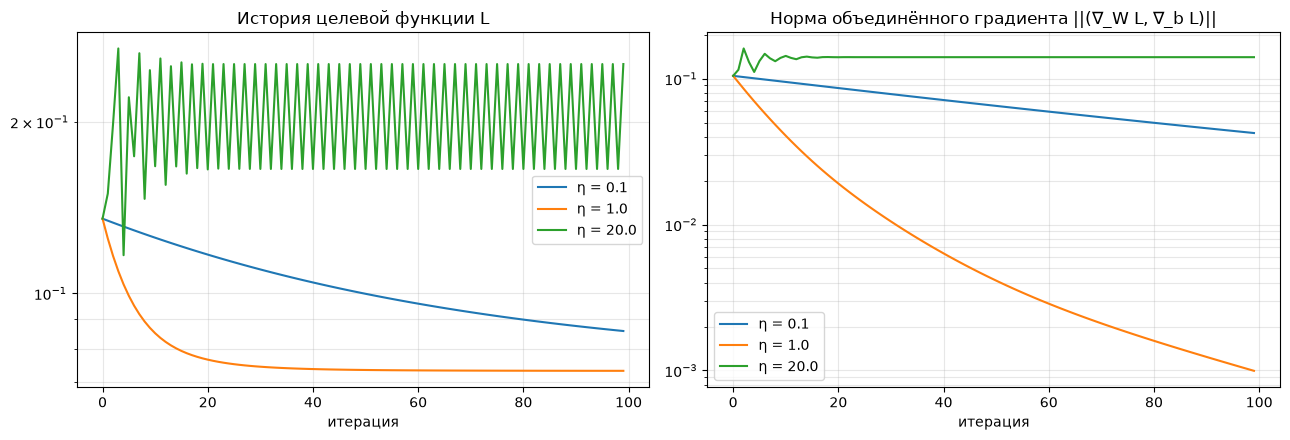

In [25]:
learning_rates = [0.1, 1.0, 20.0]
iterations = 100

def run_gradient_descent(eta, iterations):
    W, b = W_initial.copy(), b_initial.copy()
    loss_history, grad_norm_history = [], []
    for _ in range(iterations):
        loss, grad_W, grad_b = objective_and_grad(W, b)
        loss_history.append(loss)
        grad_norm_history.append(np.sqrt(np.sum(grad_W**2) + np.sum(grad_b**2)))
        W = W - eta * grad_W
        b = b - eta * grad_b
    return np.array(loss_history), np.array(grad_norm_history), W, b

_, g_W, g_b = objective_and_grad(W_initial, b_initial)
g_sq = np.sum(g_W**2) + np.sum(g_b**2)
print(f"||g||^2 в начальной точке = {g_sq:.6f}")

histories = {}
for eta in learning_rates:
    histories[eta] = run_gradient_descent(eta, iterations)
    loss_hist = histories[eta][0]
    print(f"eta = {eta:>4}: прогноз ΔL ≈ {-eta * g_sq:+.6f}, фактически {loss_hist[1] - loss_hist[0]:+.6f}")

print(f"\n{'eta':>5} | {'L начальн.':>10} | {'L конечн.':>10} | {'L мин.':>10} | {'лучшая итер.':>12} | "
      f"{'увеличений':>10} | {'||g|| конечн.':>13}")
for eta in learning_rates:
    loss_hist, grad_hist, _, _ = histories[eta]
    assert len(loss_hist) == iterations
    increases = int(np.sum(np.diff(loss_hist) > 0))
    print(f"{eta:5.1f} | {loss_hist[0]:10.6f} | {loss_hist[-1]:10.6f} | {loss_hist.min():10.6f} | "
          f"{int(loss_hist.argmin()):12d} | {increases:10d} | {grad_hist[-1]:13.3e}")
print("\nПервые 8 значений L при eta = 20:", np.round(histories[20.0][0][:8], 5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for eta in learning_rates:
    loss_hist, grad_hist, _, _ = histories[eta]
    axes[0].semilogy(loss_hist, label=f"η = {eta}")
    axes[1].semilogy(grad_hist, label=f"η = {eta}")
axes[0].set_title("История целевой функции L")
axes[1].set_title("Норма объединённого градиента ||(∇_W L, ∇_b L)||")
for ax in axes:
    ax.set_xlabel("итерация")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 10. Итоговая карта понятий

### Задание 10.1. Один язык для всех операторов

- **[Markdown]** Напишите связное резюме из 12–16 предложений, используя термины: *предел*, *производная*, *дифференциал*, *частная производная*, *градиент*, *производная по направлению*, *полная производная*, *якобиан*, *JVP*, *VJP*, *цепное правило*, *гессиан*, *след*, *матричный градиент*, *конечная разность*, *численная оптимизация*.
- **[Интерпретация]** Составьте таблицу минимум из восьми строк со столбцами: оператор, тип входа, тип выхода, размерность, какую чувствительность измеряет, как проверяется численно.
- **[Интерпретация]** Объясните на сквозной функции, где возникли суммы по индексам, где использовалось поэлементное умножение, где — матричное произведение и почему производная по $\mathbf W$ имеет размер $3\times2$.

#### Ваш итоговый ответ

**Связное резюме.**

Всё начинается с *предела* отношения приращений: *производная* $f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}$ — это локальная скорость изменения функции одной переменной. *Дифференциал* $df=f'(x)\,dx$ — главная линейная часть приращения; он превращает производную в линейную модель функции около точки. Для функции многих переменных меняют одну координату за раз и получают *частные производные*. Собранные в столбец, они образуют *градиент*, и дифференциал становится скалярным произведением $df=\nabla f^{\mathsf T}d\mathbf x$. Если подставить в него единичное направление $\mathbf v$, получится *производная по направлению* $\nabla f^{\mathsf T}\mathbf v$; её максимум $\lVert\nabla f\rVert$ достигается вдоль градиента. Когда аргументы сами зависят от параметра, *полная производная* складывает вклады всех путей зависимости — прямого и косвенных. Для векторного выхода градиенты компонент укладываются строками в *якобиан* $\mathbf J\in\mathbb R^{m\times n}$. Строить его целиком не обязательно: *JVP* $\mathbf J\mathbf v$ переносит изменение входа вперёд за два вызова функции, а *VJP* $\mathbf u^{\mathsf T}\mathbf J$ переносит чувствительность выхода назад. *Цепное правило* для композиции — произведение якобианов, поэтому градиент скалярной композиции вычисляется цепочкой VJP от выхода к входам. *Гессиан* — якобиан градиента; он описывает кривизну и по знакам собственных значений отличает минимум ($\lambda>0$) от седла (знаки разные). Для матричных параметров *след* позволяет записывать скалярные выражения вроде $\lVert\mathbf R\rVert_F^2=\operatorname{tr}(\mathbf R^{\mathsf T}\mathbf R)$ так, чтобы применять готовые тождества. Индексный вывод сворачивается в компактный *матричный градиент* формы самого параметра, например $\frac1N\mathbf X^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)$. Каждую аналитическую формулу мы проверяли *конечной разностью*: у центральной разности ошибка $O(h^2)$, но при слишком малом $h$ побеждает ошибка округления. Проверенный градиент сквозной функции стал входом *численной оптимизации*: градиентный спуск уменьшает $\mathcal L$, пока шаг $\eta$ не выводит параметры за область, где верна линейная модель. Так выход каждого оператора становится входом следующего, и путь от суммы по индексам до обучения модели описывается одним языком.

**Таблица операторов.**

| Оператор | Тип входа | Тип выхода | Размерность | Какую чувствительность измеряет | Численная проверка |
|---|---|---|---|---|---|
| Производная $f'(x)$ | скаляр $x$ | скаляр | $1$ | скорость изменения $f$ при изменении $x$ | $\frac{f(x+h/2)-f(x-h/2)}{h}$ |
| Частная производная $\partial f/\partial x_i$ | вектор $\mathbf x\in\mathbb R^n$ | скаляр | $1$ | изменение $f$ при сдвиге только $x_i$ | разность вдоль $\mathbf e_i$ |
| Градиент $\nabla f$ | вектор $\mathbf x\in\mathbb R^n$ | вектор | $n$ | чувствительность скаляра $f$ ко всем координатам | $2n$ вызовов, `central_gradient` |
| Производная по направлению $D_{\mathbf v}f$ | $\mathbf x$, единичный $\mathbf v$ | скаляр | $1$ | скорость изменения $f$ вдоль $\mathbf v$ | одна разность по скаляру $h$ |
| Полная производная $dF/dt$ | скаляр $t$ (через $x(t),y(t)$) | скаляр | $1$ | изменение $F$ по всем путям зависимости от $t$ | разность $F(t,x(t),y(t))$ |
| Якобиан $\mathbf J_{\mathbf f}$ | вектор $\mathbf x\in\mathbb R^n$ | матрица | $m\times n$ | $J_{ij}$ — влияние входа $j$ на выход $i$ | $n$ разностей (по столбцу на вход) |
| JVP $\mathbf J\mathbf v$ | $\mathbf x$, $\mathbf v\in\mathbb R^n$ | вектор | $m$ | отклик всех выходов на сдвиг входа вдоль $\mathbf v$ | 2 вызова $\mathbf f(\mathbf x\pm h\mathbf v/2)$ |
| VJP $\mathbf u^{\mathsf T}\mathbf J$ | $\mathbf x$, $\mathbf u\in\mathbb R^m$ | вектор | $n$ | влияние входов на взвешенный выход $\mathbf u^{\mathsf T}\mathbf f$ | градиент скаляра $\mathbf u^{\mathsf T}\mathbf f(\mathbf x)$ |
| Гессиан $\nabla^2f$ | вектор $\mathbf x\in\mathbb R^n$ | симметричная матрица | $n\times n$ | изменение градиента, кривизна | разности градиента по $\mathbf e_j$ |
| HVP $\mathbf H\mathbf v$ | $\mathbf x$, $\mathbf v\in\mathbb R^n$ | вектор | $n$ | изменение градиента вдоль $\mathbf v$ | $\frac{\nabla f(\mathbf x+h\mathbf v/2)-\nabla f(\mathbf x-h\mathbf v/2)}{h}$ |
| Матричный градиент $\partial f/\partial\mathbf W$ | матрица $\mathbf W\in\mathbb R^{D\times K}$ | матрица | $D\times K$ | чувствительность скаляра к каждому $W_{dk}$ | поэлементное возмущение $W_{dk}$ |

**Сквозная функция: где что возникло.**

* **Суммы по индексам.** $Z_{nk}=\sum_dX_{nd}W_{dk}+b_k$ (свёртка по $d$). Значение $\mathcal L$ — сумма по $n,k$ квадратов остатков и сумма по $d,k$ квадратов весов. В обратном проходе $(\nabla_{\mathbf W})_{dk}=\sum_nX_{nd}(G_Z)_{nk}$ — свёртка по наблюдениям $n$, а $(\nabla_{\mathbf b})_k=\sum_n(G_Z)_{nk}$ — сумма по строкам.
* **Поэлементное умножение $\odot$.** Сигмоида и её производная $\sigma'=\mathbf H\odot(1-\mathbf H)$, переход $\mathbf G_Z=\mathbf G_H\odot\mathbf H\odot(1-\mathbf H)$ (диагональный якобиан поэлементной функции), квадраты в нормах.
* **Матричное произведение.** $\mathbf X\mathbf W$ в прямом проходе; $\mathbf X^{\mathsf T}\mathbf G_Z$ и $\mathbf G_Z^{\mathsf T}\mathbf 1_N$ в обратном; внешнее произведение $\mathbf 1_N\mathbf b^{\mathsf T}$ при расширении смещения.
* **Почему $\nabla_{\mathbf W}\mathcal L$ имеет размер $3\times2$.** $\mathcal L$ — скаляр, а параметр $\mathbf W$ содержит $D\cdot K=6$ чисел. Для каждого $W_{dk}$ есть своя частная производная $\partial\mathcal L/\partial W_{dk}$, и её кладут на то же место $(d,k)$. Размерности согласуются: $\mathbf X^{\mathsf T}\,(3\times4)$ умножить на $\mathbf G_Z\,(4\times2)$ — это $3\times2$, и $\lambda\mathbf W$ тоже $3\times2$. Поэтому шаг $\mathbf W-\eta\nabla_{\mathbf W}\mathcal L$ определён поэлементно.

## Что сдавать

Сдаётся заполненный студенческий ноутбук с сохранёнными результатами выполнения всех ячеек.

Перед отправкой проверьте:

- каждое ручное решение содержит формулу, подстановку и промежуточные действия;
- свободные и суммируемые индексы различаются корректно;
- размерности подписаны у градиентов, якобианов, JVP, VJP и гессианов;
- численные производные сравниваются с аналитическими по норме ошибки;
- стационарные точки классифицированы по кривизне, а не только по нулевому градиенту;
- матричные градиенты выведены и проверены по каждому элементу;
- максимальная ошибка проверки сквозной функции меньше $10^{-6}$;
- истории оптимизации начинаются из одной точки и содержат 100 значений;
- интерпретации ссылаются на конкретные числа и графики;
- все ячейки выполняются сверху вниз без ошибок.

## Краткая справка NumPy

```python
A @ B                              # матричное произведение
A * B                              # поэлементное произведение
np.einsum("ik,kj->ij", A, B)       # свёртка по индексам
np.outer(a, b)                     # внешнее произведение
np.trace(A)                        # след
np.linalg.norm(A, ord="fro")       # норма Фробениуса
np.linalg.eigvalsh(H)              # собственные значения симметричной матрицы
np.clip(z, -50.0, 50.0)            # ограничение перед exp
```

Все данные заданы внутри ноутбука. Интернет и дополнительные библиотеки не требуются.